# Tyre model comparison studio
## Low · Medium · High — five models, one consistent view

This notebook **runs inference only** using all five current Phase 2 model families: MobileNet V4 Medium, ResNet50, YOLO26 Medium segmentation, SegFormer B0 and HRNet W18. It uses the same validation-selected exports as Tread Station, not every historical architecture or training seed.

Each example gets a six-panel inspection card: original photo, two probability plots, two transparent region overlays, and a learned-boundary comparison. A probability fingerprint and a light-theme HTML gallery bring the examples together. No model is selected using the displayed predictions.

### Before Run All
1. Import this notebook into Kaggle. Choose **T4 ×2** (one GPU is sufficient; inference keeps only one model on GPU 0 at a time to save memory).
2. Enable Internet and the **HF_TOKEN** secret with write permission to `Shanmuk4622/tyre-wear-study`.
3. Attach [Tire Dataset Prepared phase2](https://www.kaggle.com/datasets/shanmuk4622/tire-dataset-prepared-phase2) directly as a Kaggle input. No dataset download from HF and no repository upload are needed.
4. Keep the defaults for three examples per category, or attach your own `low/`, `medium/`, `high/` image folders and set `CUSTOM_ROOT` below.
5. Run top to bottom. Open the inline cards, then download the gallery ZIP from the final cell.

**Interpretation:** supplied classes are mileage proxies. Medium examples from the prepared collection are training images; low/high defaults use test images. These few selected examples are qualitative illustrations, not a new accuracy benchmark. Boundary agreement is not physical alignment accuracy. Softmax scores are uncalibrated.


In [1]:
# Change these before running. Keep RUN_TAG unchanged when resuming.
PER_CLASS = 3
DATA_ROOT = ''       # Auto-detect the attached prepared Phase 2 dataset.
CUSTOM_ROOT = ''     # Example: '/kaggle/input/my-tyres/photos' with low/medium/high.
RUN_TAG = 'first-comparison'  # New tag for a separate gallery; never run duplicate writers.
PUBLISH_TO_HF = True # Saves overlays + predictions to your existing HF dataset repository.


## 1 · Prepare the small runtime
The notebook embeds the exact model code and export registry. It downloads only five checkpoint files (about 278 MiB total). Prepared images stay in read-only Kaggle input. It never trains, copies the full dataset, or assumes 1 TB of storage.


In [2]:
import os, sys, subprocess, base64, json, hashlib, re
from pathlib import Path
WORK = Path('/kaggle/working/tyre_visual_comparison')
WORK.mkdir(parents=True, exist_ok=True)
RUNTIME = WORK/'runtime'; RUNTIME.mkdir(exist_ok=True)
DEPS = WORK/'deps'
os.environ['YOLO_CONFIG_DIR'] = str(WORK/'yolo_settings')
(WORK/'yolo_settings'/'Ultralytics').mkdir(parents=True, exist_ok=True)
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '--no-input',
    '--disable-pip-version-check', '--no-deps', '--upgrade', '--target', str(DEPS),
    'timm==1.0.15', 'ultralytics==8.4.20', 'ultralytics-thop==2.0.18',
    'transformers==4.51.3', 'tokenizers==0.21.4', 'huggingface_hub==0.36.0',
    'safetensors==0.5.3', 'filelock==3.19.1'], timeout=600)
# Start with a fresh kernel if these packages were imported in another notebook cell.
sys.path[:0] = [str(DEPS), str(RUNTIME)]
(RUNTIME/'phase2_models.py').write_bytes(base64.b64decode('IiIiRXhwbGljaXQgUGhhc2UgMiBtb2RlbCBhZGFwdGVycy4gTm8gb2xkIHR5cmUtdHJhaW5lZCBpbml0aWFsaXphdGlvbi4iIiIKZnJvbSBQSUwgaW1wb3J0IEltYWdlICAjIExvYWQgaW1hZ2luZyBETExzIGJlZm9yZSB0b3JjaCBvbiB0aGUgbG9jYWwgV2luZG93cyB0ZXN0IGhvc3QuCmltcG9ydCBjb3B5CmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHRvcmNoCmZyb20gdG9yY2ggaW1wb3J0IG5uCmltcG9ydCB0b3JjaC5ubi5mdW5jdGlvbmFsIGFzIEYKZnJvbSBwaGFzZTJfdHJhaW5pbmdfZGF0YSBpbXBvcnQgU1BFQ1MsIHNhbXBsZQoKX0lOVEVSUE9MQVRFPUYuaW50ZXJwb2xhdGUKY2xhc3MgRGV0ZXJtaW5pc3RpY0JpbGluZWFyKHRvcmNoLmF1dG9ncmFkLkZ1bmN0aW9uKToKIEBzdGF0aWNtZXRob2QKIGRlZiBmb3J3YXJkKGN0eCx4LHNpemUpOgogIGN0eC5odz14LnNoYXBlWy0yOl07Y3R4LmR0eXBlPXguZHR5cGUKICByZXR1cm4gX0lOVEVSUE9MQVRFKHguZmxvYXQoKSxzaXplPXNpemUsbW9kZT0nYmlsaW5lYXInLGFsaWduX2Nvcm5lcnM9RmFsc2UpLnRvKHguZHR5cGUpCiBAc3RhdGljbWV0aG9kCiBkZWYgYmFja3dhcmQoY3R4LGcpOgogIGRlZiB3ZWlnaHRzKG4sbSk6CiAgIHA9KCh0b3JjaC5hcmFuZ2UobSxkZXZpY2U9Zy5kZXZpY2UsZHR5cGU9dG9yY2guZmxvYXQzMikrLjUpKm4vbS0uNSkuY2xhbXAoMCxuLTEpCiAgIGxvPXAuZmxvb3IoKS5sb25nKCk7aGk9KGxvKzEpLmNsYW1wX21heChuLTEpO2Y9cC1sbztjPXRvcmNoLmFyYW5nZShuLGRldmljZT1nLmRldmljZSkKICAgcmV0dXJuIChjW05vbmUsOl09PWxvWzosTm9uZV0pKigxLWZbOixOb25lXSkrKGNbTm9uZSw6XT09aGlbOixOb25lXSkqZls6LE5vbmVdCiAgd2l0aCB0b3JjaC5hdXRvY2FzdChnLmRldmljZS50eXBlLGVuYWJsZWQ9RmFsc2UpOgogICB5PXdlaWdodHMoY3R4Lmh3WzBdLGcuc2hhcGVbLTJdKTt4PXdlaWdodHMoY3R4Lmh3WzFdLGcuc2hhcGVbLTFdKTtyZXN1bHQ9eS5UQGcuZmxvYXQoKUB4CiAgcmV0dXJuIHJlc3VsdC50byhjdHguZHR5cGUpLE5vbmUKCmRlZiBkZXRlcm1pbmlzdGljX3Jlc2l6ZShpbnB1dCxzaXplPU5vbmUsc2NhbGVfZmFjdG9yPU5vbmUsbW9kZT0nbmVhcmVzdCcsYWxpZ25fY29ybmVycz1Ob25lLHJlY29tcHV0ZV9zY2FsZV9mYWN0b3I9Tm9uZSxhbnRpYWxpYXM9RmFsc2UpOgogaWYgbW9kZT09J2JpbGluZWFyJyBhbmQgaW5wdXQucmVxdWlyZXNfZ3JhZCBhbmQgdG9yY2guaXNfZ3JhZF9lbmFibGVkKCkgYW5kIGFsaWduX2Nvcm5lcnMgaXMgRmFsc2UgYW5kIHNpemUgaXMgbm90IE5vbmUgYW5kIHNjYWxlX2ZhY3RvciBpcyBOb25lIGFuZCBub3QgYW50aWFsaWFzOgogIHJldHVybiBEZXRlcm1pbmlzdGljQmlsaW5lYXIuYXBwbHkoaW5wdXQsKHNpemUsc2l6ZSkgaWYgaXNpbnN0YW5jZShzaXplLGludCkgZWxzZSB0dXBsZShzaXplKSkKIHJldHVybiBfSU5URVJQT0xBVEUoaW5wdXQsc2l6ZT1zaXplLHNjYWxlX2ZhY3Rvcj1zY2FsZV9mYWN0b3IsbW9kZT1tb2RlLGFsaWduX2Nvcm5lcnM9YWxpZ25fY29ybmVycyxyZWNvbXB1dGVfc2NhbGVfZmFjdG9yPXJlY29tcHV0ZV9zY2FsZV9mYWN0b3IsYW50aWFsaWFzPWFudGlhbGlhcykKCmRlZiBkZXRlcm1pbmlzdGljKCk6CiB0b3JjaC51c2VfZGV0ZXJtaW5pc3RpY19hbGdvcml0aG1zKFRydWUpCiB0b3JjaC5iYWNrZW5kcy5jdWRubi5iZW5jaG1hcms9RmFsc2U7dG9yY2guYmFja2VuZHMuY3Vkbm4uZGV0ZXJtaW5pc3RpYz1UcnVlCiB0b3JjaC5iYWNrZW5kcy5jdWRhLm1hdG11bC5hbGxvd190ZjMyPUZhbHNlO3RvcmNoLmJhY2tlbmRzLmN1ZG5uLmFsbG93X3RmMzI9RmFsc2UKIEYuaW50ZXJwb2xhdGU9ZGV0ZXJtaW5pc3RpY19yZXNpemUKCmNsYXNzIEdlb21ldHJ5KG5uLk1vZHVsZSk6CiBkZWYgX19pbml0X18oc2VsZik6CiAgc3VwZXIoKS5fX2luaXRfXygpO2ltcG9ydCB0aW1tCiAgc2VsZi5iYWNrYm9uZT10aW1tLmNyZWF0ZV9tb2RlbChTUEVDU1snaHJuZXQnXVsnbW9kZWwnXSxwcmV0cmFpbmVkPUZhbHNlLGZlYXR1cmVzX29ubHk9VHJ1ZSxmZWF0dXJlX2xvY2F0aW9uPScnLG91dF9pbmRpY2VzPSgxLDIsMyw0KSkKICBjaD1zZWxmLmJhY2tib25lLmZlYXR1cmVfaW5mby5jaGFubmVscygpO2Fzc2VydCBjaD09WzE4LDM2LDcyLDE0NF0KICBzZWxmLnByb2plY3Rpb25zPW5uLk1vZHVsZUxpc3Qobm4uQ29udjJkKGMsMTYsMSkgZm9yIGMgaW4gY2gpCiAgc2VsZi5oZWFkPW5uLlNlcXVlbnRpYWwobm4uQ29udjJkKDY0LDY0LDMscGFkZGluZz0xKSxubi5SZUxVKCksbm4uQ29udjJkKDY0LDYsMSkpCiBkZWYgZm9yd2FyZChzZWxmLHgpOgogIG1hcHM9c2VsZi5iYWNrYm9uZSh4KTtzaXplPW1hcHNbMF0uc2hhcGVbLTI6XQogIGhlYXQ9c2VsZi5oZWFkKHRvcmNoLmNhdChbRi5pbnRlcnBvbGF0ZShwKG0pLHNpemU9c2l6ZSxtb2RlPSduZWFyZXN0JykgZm9yIHAsbSBpbiB6aXAoc2VsZi5wcm9qZWN0aW9ucyxtYXBzKV0sMSkpCiAgbGluZXM9W10KICBmb3IgaSBpbiByYW5nZSg2KToKICAgcG9zPShoZWF0LnNoYXBlWy0yXS0xKSooWzM4NC8xNTM1LDc2OC8xNTM1LDExNTEvMTUzNV1baS8vMl0pO2xvPWludChwb3MpO2Y9cG9zLWxvCiAgIGxpbmVzLmFwcGVuZChoZWF0WzosaSxsbyw6XSooMS1mKStoZWF0WzosaSxtaW4obG8rMSxoZWF0LnNoYXBlWy0yXS0xKSw6XSpmKQogIHJldHVybiB0b3JjaC5zdGFjayhsaW5lcywxKQoKZGVmIGJ1aWxkKG5hbWUsYXNzZXRzLHByZXRyYWluZWQ9VHJ1ZSxkZXZpY2U9J2N1ZGEnKToKIHNwZWM9U1BFQ1NbbmFtZV07YXNzZXRzPVBhdGgoYXNzZXRzKQogaWYgbmFtZSBpbiAoJ21vYmlsZW5ldHY0JywncmVzbmV0NTAnLCdocm5ldCcpOgogIGltcG9ydCB0aW1tCiAgYXNzZXJ0IHRpbW0uX192ZXJzaW9uX189PScxLjAuMTUnCiAgbW9kZWw9R2VvbWV0cnkoKSBpZiBuYW1lPT0naHJuZXQnIGVsc2UgdGltbS5jcmVhdGVfbW9kZWwoc3BlY1snbW9kZWwnXSxwcmV0cmFpbmVkPUZhbHNlLG51bV9jbGFzc2VzPTMpCiAgaWYgcHJldHJhaW5lZDoKICAgZnJvbSBzYWZldGVuc29ycy50b3JjaCBpbXBvcnQgbG9hZF9maWxlCiAgIHN0YXRlPWxvYWRfZmlsZShzdHIoYXNzZXRzL25hbWUvJ21vZGVsLnNhZmV0ZW5zb3JzJykpCiAgIHRhcmdldD1tb2RlbC5iYWNrYm9uZSBpZiBuYW1lPT0naHJuZXQnIGVsc2UgbW9kZWwKICAga2V5cz10YXJnZXQuc3RhdGVfZGljdCgpOyBzZWxlY3RlZD17fQogICBmb3Igayx2IGluIGtleXMuaXRlbXMoKToKICAgIGlmIG5hbWUhPSdocm5ldCcgYW5kIGsuc3RhcnRzd2l0aCgoJ2NsYXNzaWZpZXIuJywnZmMuJykpOnNlbGVjdGVkW2tdPXYKICAgIGVsaWYgayBpbiBzdGF0ZSBhbmQgc3RhdGVba10uc2hhcGU9PXYuc2hhcGU6c2VsZWN0ZWRba109c3RhdGVba10KICAgIGVsaWYgay5lbmRzd2l0aCgnbnVtX2JhdGNoZXNfdHJhY2tlZCcpOnNlbGVjdGVkW2tdPXYKICAgIGVsc2U6cmFpc2UgVmFsdWVFcnJvcignUHJldHJhaW5lZCB0ZW5zb3IgbWlzbWF0Y2g6ICcraykKICAgdGFyZ2V0LmxvYWRfc3RhdGVfZGljdChzZWxlY3RlZCxzdHJpY3Q9VHJ1ZSkKIGVsaWYgbmFtZT09J3NlZ2Zvcm1lcic6CiAgZnJvbSB0cmFuc2Zvcm1lcnMgaW1wb3J0IFNlZ2Zvcm1lckNvbmZpZyxTZWdmb3JtZXJGb3JTZW1hbnRpY1NlZ21lbnRhdGlvbixTZWdmb3JtZXJNb2RlbAogIGNmZz1TZWdmb3JtZXJDb25maWcuZnJvbV9wcmV0cmFpbmVkKHN0cihhc3NldHMvbmFtZSksbG9jYWxfZmlsZXNfb25seT1UcnVlKTtjZmcubnVtX2xhYmVscz0yCiAgbW9kZWw9U2VnZm9ybWVyRm9yU2VtYW50aWNTZWdtZW50YXRpb24oY2ZnKQogIGlmIHByZXRyYWluZWQ6CiAgIGVuY29kZXI9U2VnZm9ybWVyTW9kZWwuZnJvbV9wcmV0cmFpbmVkKHN0cihhc3NldHMvbmFtZSksbG9jYWxfZmlsZXNfb25seT1UcnVlLHVzZV9zYWZldGVuc29ycz1GYWxzZSkKICAgbW9kZWwuc2VnZm9ybWVyLmxvYWRfc3RhdGVfZGljdChlbmNvZGVyLnN0YXRlX2RpY3QoKSxzdHJpY3Q9VHJ1ZSk7ZGVsIGVuY29kZXIKIGVsaWYgbmFtZT09J3lvbG8yNm0nOgogIGZyb20gdWx0cmFseXRpY3Mubm4udGFza3MgaW1wb3J0IFNlZ21lbnRhdGlvbk1vZGVsCiAgZnJvbSB1bHRyYWx5dGljcy5jZmcgaW1wb3J0IGdldF9jZmcKICBtb2RlbD1TZWdtZW50YXRpb25Nb2RlbChzcGVjWydtb2RlbCddLGNoPTMsbmM9Mix2ZXJib3NlPUZhbHNlKQogIG1vZGVsLmFyZ3M9Z2V0X2NmZyhvdmVycmlkZXM9ZGljdCh0YXNrPSdzZWdtZW50JyxvdmVybGFwX21hc2s9RmFsc2UsZXBvY2hzPTYwLGJveD03LjUsY2xzPS41LGRmbD0xLjUpKQogIGlmIHByZXRyYWluZWQ6CiAgICMgT2ZmaWNpYWwgdXBzdHJlYW0gYXNzZXQgb25seTsgZmlsZSBoYXNoIGlzIGZyb3plbiBpbiB0aGUgcnVuIGNvbnRyYWN0LgogICBja3B0PXRvcmNoLmxvYWQoYXNzZXRzL25hbWUvJ3lvbG8yNm0tc2VnLnB0JyxtYXBfbG9jYXRpb249J2NwdScsd2VpZ2h0c19vbmx5PUZhbHNlKQogICBvcmlnaW5hbD1ja3B0LmdldCgnZW1hJykgb3IgY2twdFsnbW9kZWwnXTttb2RlbC5sb2FkKG9yaWdpbmFsLmZsb2F0KCksdmVyYm9zZT1GYWxzZSk7ZGVsIGNrcHQsb3JpZ2luYWwKICAjIE5hdGl2ZSBZT0xPMjYgYXV4aWxpYXJ5IHNlbWFudGljIGxvc3MgYXNzdW1lcyBleGNsdXNpdmUgY2xhc3Nlcy4gT3VyIG5lc3RlZAogICMgdHlyZS90cmVhZCBpbnN0YW5jZXMgcmVtYWluIG92ZXJsYXBwaW5nOyBkaXNhYmxlIG9ubHkgdGhhdCBhdXhpbGlhcnkgYnJhbmNoLgogICMgSW5zdGFuY2UgbWFza3MsIGJvdGggZGV0ZWN0aW9uIGhlYWRzIGFuZCB0aGVpciBvcmRpbmFyeSBsb3NzZXMgcmVtYWluIGFjdGl2ZS4KICBtb2RlbC5uYW1lcz17MDondHlyZScsMTondHJlYWQnfQogZWxzZTpyYWlzZSBWYWx1ZUVycm9yKG5hbWUpCiBtb2RlbD1tb2RlbC50byhkZXZpY2UpCiBpZiBuYW1lPT0neW9sbzI2bSc6bW9kZWwuY3JpdGVyaW9uPW1vZGVsLmluaXRfY3JpdGVyaW9uKCkKIHJldHVybiBtb2RlbAoKZGVmIHRyYWluaW5nX21vZGUobW9kZWwpOgogbW9kZWwudHJhaW4oKQogZm9yIGxheWVyIGluIG1vZGVsLm1vZHVsZXMoKToKICBpZiBpc2luc3RhbmNlKGxheWVyLG5uLm1vZHVsZXMuYmF0Y2hub3JtLl9CYXRjaE5vcm0pOmxheWVyLmV2YWwoKQoKZGVmIGJhdGNoKHJvb3Qscm93cyxuYW1lLGVwb2NoPTAsc3RlcD0wLHNlZWQ9Tm9uZSxkZXZpY2U9J2N1ZGEnKToKIGFycmF5cz1bc2FtcGxlKHJvb3QscixTUEVDU1tuYW1lXVsnaHcnXSxOb25lIGlmIHNlZWQgaXMgTm9uZSBlbHNlIHNlZWQqMTAwMDAwMTkrZXBvY2gqMTAwMDAzK3N0ZXAqOTcraSxuYW1lKSBmb3IgaSxyIGluIGVudW1lcmF0ZShyb3dzKV0KIHg9dG9yY2gudGVuc29yKG5wLnN0YWNrKFt2WzBdIGZvciB2IGluIGFycmF5c10pLGRldmljZT1kZXZpY2UpCiBtYXNrcz10b3JjaC50ZW5zb3IobnAuc3RhY2soW3ZbMV0gZm9yIHYgaW4gYXJyYXlzXSksZGV2aWNlPWRldmljZSkKIHBvaW50cz10b3JjaC50ZW5zb3IobnAuc3RhY2soW3ZbMl0gZm9yIHYgaW4gYXJyYXlzXSksZGV2aWNlPWRldmljZSkKIGlmIG5hbWUhPSd5b2xvMjZtJzp4PSh4LXgubmV3X3RlbnNvcihbLjQ4NSwuNDU2LC40MDZdKVtOb25lLDosTm9uZSxOb25lXSkveC5uZXdfdGVuc29yKFsuMjI5LC4yMjQsLjIyNV0pW05vbmUsOixOb25lLE5vbmVdCiByZXN1bHQ9ZGljdChpbWc9eCxtYXNrcz1tYXNrcyxwb2ludHM9cG9pbnRzLGxhYmVscz10b3JjaC50ZW5zb3IoW3JbJ2NsYXNzX2luZGV4J10gZm9yIHIgaW4gcm93c10sZGV2aWNlPWRldmljZSkscG9pbnRfd2VpZ2h0PXgubmV3X3RlbnNvcihbclsncG9pbnRfd2VpZ2h0J10gZm9yIHIgaW4gcm93c10pKQogaWYgbmFtZT09J3lvbG8yNm0nOgogIGJveGVzPVtdO2luZGljZXM9W107Y2xhc3Nlcz1bXTtpbnN0YW5jZXM9W107aCx3PXguc2hhcGVbLTI6XQogIGZvciBpIGluIHJhbmdlKGxlbihyb3dzKSk6CiAgIGZvciBjIGluICgwLDEpOgogICAgeSx6PXRvcmNoLndoZXJlKG1hc2tzW2ksY10pO2Fzc2VydCBsZW4oeiksJ0VtcHR5IHJlc2l6ZWQgWU9MTyB0YXJnZXQnCiAgICB4MCx4MT16Lm1pbigpLHoubWF4KCkrMTt5MCx5MT15Lm1pbigpLHkubWF4KCkrMQogICAgYm94ZXMuYXBwZW5kKHRvcmNoLnN0YWNrKCgoeDAreDEpLzIvdywoeTAreTEpLzIvaCwoeDEteDApL3csKHkxLXkwKS9oKSkpCiAgICBpbmRpY2VzLmFwcGVuZChpKTtjbGFzc2VzLmFwcGVuZChjKTtpbnN0YW5jZXMuYXBwZW5kKG1hc2tzW2ksY10uZmxvYXQoKSkKICByZXN1bHQudXBkYXRlKGJib3hlcz10b3JjaC5zdGFjayhib3hlcyksYmF0Y2hfaWR4PXRvcmNoLnRlbnNvcihpbmRpY2VzLGRldmljZT1kZXZpY2UpLGNscz14Lm5ld190ZW5zb3IoY2xhc3NlcykudmlldygtMSwxKSxtYXNrcz10b3JjaC5zdGFjayhpbnN0YW5jZXMpKQogcmV0dXJuIHJlc3VsdAoKZGVmIHdpdGhvdXRfc2VtYW50aWMocHJlZCk6CiBpZiBpc2luc3RhbmNlKHByZWQsZGljdCk6CiAgb3V0PXtrOndpdGhvdXRfc2VtYW50aWModikgZm9yIGssdiBpbiBwcmVkLml0ZW1zKCl9CiAgaWYgaXNpbnN0YW5jZShvdXQuZ2V0KCdwcm90bycpLHR1cGxlKTpvdXRbJ3Byb3RvJ109b3V0Wydwcm90byddWzBdCiAgcmV0dXJuIG91dAogcmV0dXJuIHByZWQKCmRlZiBsb3NzKG1vZGVsLGIsbmFtZSxlcG9jaCk6CiBpZiBuYW1lIGluICgnbW9iaWxlbmV0djQnLCdyZXNuZXQ1MCcpOnJldHVybiBGLmNyb3NzX2VudHJvcHkobW9kZWwoYlsnaW1nJ10pLmZsb2F0KCksYlsnbGFiZWxzJ10sbGFiZWxfc21vb3RoaW5nPS4wNSkKIGlmIG5hbWU9PSdocm5ldCc6CiAgej1tb2RlbChiWydpbWcnXSkuZmxvYXQoKTtncmlkPXRvcmNoLmFyYW5nZSh6LnNoYXBlWy0xXSxkZXZpY2U9ei5kZXZpY2UpCiAgdGFyZ2V0PXRvcmNoLmV4cCgtLjUqKChncmlkLWJbJ3BvaW50cyddWy4uLixOb25lXSooei5zaGFwZVstMV0tMSkpLzEuNSkqKjIpCiAgdGFyZ2V0PXRhcmdldC90YXJnZXQuc3VtKC0xLGtlZXBkaW09VHJ1ZSkuY2xhbXBfbWluKDFlLTEyKQogIHZhbHVlcz0tKHRhcmdldCp6LmxvZ19zb2Z0bWF4KC0xKSkuc3VtKC0xKS5tZWFuKC0xKQogIHJldHVybiAodmFsdWVzKmJbJ3BvaW50X3dlaWdodCddKS5tZWFuKCkKIGlmIG5hbWU9PSdzZWdmb3JtZXInOgogIHo9Ri5pbnRlcnBvbGF0ZShtb2RlbChwaXhlbF92YWx1ZXM9YlsnaW1nJ10pLmxvZ2l0cy5mbG9hdCgpLGJbJ21hc2tzJ10uc2hhcGVbLTI6XSxtb2RlPSdiaWxpbmVhcicsYWxpZ25fY29ybmVycz1GYWxzZSkKICB5PWJbJ21hc2tzJ11bOiw6Ml0uZmxvYXQoKTt2YWxpZD0ofmJbJ21hc2tzJ11bOiwyOjNdKS5mbG9hdCgpO3A9ei5zaWdtb2lkKCkKICBiY2U9KEYuYmluYXJ5X2Nyb3NzX2VudHJvcHlfd2l0aF9sb2dpdHMoeix5LHJlZHVjdGlvbj0nbm9uZScpKnZhbGlkKS5zdW0oKS8odmFsaWQuc3VtKCkqMikuY2xhbXBfbWluKDEpCiAgZGltcz0oMCwyLDMpO2RpY2U9KDIqKHAqeSp2YWxpZCkuc3VtKGRpbXMpKzEpLygocCp2YWxpZCkuc3VtKGRpbXMpKyh5KnZhbGlkKS5zdW0oZGltcykrMSkKICByZXR1cm4gYmNlKzEtZGljZS5tZWFuKCkKIGlmIG5hbWU9PSd5b2xvMjZtJzoKICBjcml0ZXJpb249bW9kZWwuY3JpdGVyaW9uCiAgIyBUaGUgdXBzdHJlYW0gcHJvZ3Jlc3NpdmUgbG9zcyBoYXMgbXV0YWJsZSBlcG9jaCB3ZWlnaHRpbmcuIFNldCBleHBsaWNpdGx5CiAgIyBmcm9tIHNhdmVkIGVwb2NoIHJhdGhlciB0aGFuIHJlbHlpbmcgb24gZnJhbWV3b3JrIGNhbGxiYWNrcy4KICBpZiBoYXNhdHRyKGNyaXRlcmlvbiwnbzJtJyk6CiAgIGNyaXRlcmlvbi5vMm09Y3JpdGVyaW9uLmRlY2F5KGVwb2NoKTtjcml0ZXJpb24ubzJvPTEtY3JpdGVyaW9uLm8ybQogIHByZWQ9d2l0aG91dF9zZW1hbnRpYyhtb2RlbChiWydpbWcnXSkpCiAgcmV0dXJuIGNyaXRlcmlvbihwcmVkLGIpWzBdLnN1bSgpL2xlbihiWydpbWcnXSkKIHJhaXNlIFZhbHVlRXJyb3IobmFtZSkKCmRlZiBwcmVkaWN0KG1vZGVsLGIsbmFtZSk6CiBpZiBuYW1lIGluICgnbW9iaWxlbmV0djQnLCdyZXNuZXQ1MCcpOnJldHVybiBtb2RlbChiWydpbWcnXSkuZmxvYXQoKS5zb2Z0bWF4KC0xKQogaWYgbmFtZT09J2hybmV0JzoKICB6PW1vZGVsKGJbJ2ltZyddKS5mbG9hdCgpO3JldHVybiAoei5zb2Z0bWF4KC0xKSp0b3JjaC5saW5zcGFjZSgwLDEsei5zaGFwZVstMV0sZGV2aWNlPXouZGV2aWNlKSkuc3VtKC0xKQogaWYgbmFtZT09J3NlZ2Zvcm1lcic6cmV0dXJuIEYuaW50ZXJwb2xhdGUobW9kZWwocGl4ZWxfdmFsdWVzPWJbJ2ltZyddKS5sb2dpdHMuZmxvYXQoKSxiWydpbWcnXS5zaGFwZVstMjpdLG1vZGU9J2JpbGluZWFyJyxhbGlnbl9jb3JuZXJzPUZhbHNlKS5zaWdtb2lkKCk+PS41CiBpZiBuYW1lPT0neW9sbzI2bSc6CiAgZnJvbSB1bHRyYWx5dGljcy51dGlscy5vcHMgaW1wb3J0IHByb2Nlc3NfbWFzawogIG91dD1tb2RlbChiWydpbWcnXSk7cGFpcj1vdXRbMF0gaWYgaXNpbnN0YW5jZShvdXRbMF0sdHVwbGUpIGVsc2Ugb3V0CiAgZGV0ZWN0aW9ucyxwcm90bz1wYWlyCiAgcmVzdWx0PXRvcmNoLnplcm9zKChsZW4oYlsnaW1nJ10pLDIsKmJbJ2ltZyddLnNoYXBlWy0yOl0pLGR0eXBlPXRvcmNoLmJvb2wsZGV2aWNlPWJbJ2ltZyddLmRldmljZSkKICBmb3IgaSxkZXQgaW4gZW51bWVyYXRlKGRldGVjdGlvbnMpOgogICBkZXQ9ZGV0W2RldFs6LDRdPj0uMjVdCiAgIGlmIG5vdCBsZW4oZGV0KTpjb250aW51ZQogICBtYXNrcz1wcm9jZXNzX21hc2socHJvdG9baV0sZGV0WzosNjpdLGRldFs6LDo0XSxiWydpbWcnXS5zaGFwZVstMjpdLHVwc2FtcGxlPVRydWUpLmJvb2woKQogICBmb3IgYyBpbiAoMCwxKToKICAgIGhpdD1kZXRbOiw1XS5sb25nKCk9PWMKICAgIGlmIGhpdC5hbnkoKTpyZXN1bHRbaSxjXT1tYXNrc1toaXRdLmFueSgwKQogIHJldHVybiByZXN1bHQK'))
(RUNTIME/'phase2_training_data.py').write_bytes(base64.b64decode('IiIiVmVyc2lvbmVkIHRyYWluaW5nIG92ZXJsYXk7IHNvdXJjZS12MSBpcyBhbHdheXMgcmVhZC1vbmx5LiIiIgppbXBvcnQgaGFzaGxpYgppbXBvcnQganNvbgppbXBvcnQgbWF0aApmcm9tIGNvbGxlY3Rpb25zIGltcG9ydCBDb3VudGVyCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgbnVtcHkgYXMgbnAKZnJvbSBQSUwgaW1wb3J0IEltYWdlLCBJbWFnZUVuaGFuY2UsIEltYWdlRmlsdGVyCgpSRUxFQVNFX1NIQSA9ICcwNmM2YzlkMDAzYWZmODA4YmFiZjdlYmI1Nzg2ZjQ0MWU5NTA2NGViMDAwZjVlNWVkNWIxNTVkMGVlOWU3YzZhJwpSRVZJU0lPTiA9ICdwaGFzZTItdHJhaW5pbmctcjEnCk1PREVMUyA9IFsnbW9iaWxlbmV0djQnLCAncmVzbmV0NTAnLCAnc2VnZm9ybWVyJywgJ3lvbG8yNm0nLCAnaHJuZXQnXQpTUEVDUyA9IHsKICdtb2JpbGVuZXR2NCc6IGRpY3QobW9kZWw9J21vYmlsZW5ldHY0X2NvbnZfbWVkaXVtLmU1MDBfcjI1Nl9pbjFrJywgcmVwbz0ndGltbS9tb2JpbGVuZXR2NF9jb252X21lZGl1bS5lNTAwX3IyNTZfaW4xaycsIHJldmlzaW9uPSdhZDY2ODk4YzA0NWMxYjUyMjNlYTNmMmMwODMwYjc0Y2YyZTc1YmFjJywgZmlsZT0nbW9kZWwuc2FmZXRlbnNvcnMnLCBodz1bMzg0LDM4NF0sIGJhdGNoPTgpLAogJ3Jlc25ldDUwJzogZGljdChtb2RlbD0ncmVzbmV0NTAuYTFfaW4xaycsIHJlcG89J3RpbW0vcmVzbmV0NTAuYTFfaW4xaycsIHJldmlzaW9uPSc3NjcyNjg2MDNjYTBjYjBiZmUzMjZmYTg3Mjc3ZjE5YzQxOTU2NmVmJywgZmlsZT0nbW9kZWwuc2FmZXRlbnNvcnMnLCBodz1bMzg0LDM4NF0sIGJhdGNoPTgpLAogJ3NlZ2Zvcm1lcic6IGRpY3QobW9kZWw9J252aWRpYS9taXQtYjAnLCByZXBvPSdudmlkaWEvbWl0LWIwJywgcmV2aXNpb249JzgwOTgzYTQxM2MzMGQzNmEzOWMyMDIwMzk3NGFlNzgwNzgzNWUyYjQnLCBmaWxlPSdweXRvcmNoX21vZGVsLmJpbicsIGh3PVs1MTIsMzg0XSwgYmF0Y2g9MiksCiAnaHJuZXQnOiBkaWN0KG1vZGVsPSdocm5ldF93MTgubXNfYXVnX2luMWsnLCByZXBvPSd0aW1tL2hybmV0X3cxOC5tc19hdWdfaW4xaycsIHJldmlzaW9uPSc3ZTJjNTU4Mzc2OWY1NDUxNGZkODdlM2JhOWRlNDA4ZTMzZWFiYTBmJywgZmlsZT0nbW9kZWwuc2FmZXRlbnNvcnMnLCBodz1bNTEyLDM4NF0sIGJhdGNoPTIpLAogJ3lvbG8yNm0nOiBkaWN0KG1vZGVsPSd5b2xvMjZtLXNlZy55YW1sJywgdXJsPSdodHRwczovL2dpdGh1Yi5jb20vdWx0cmFseXRpY3MvYXNzZXRzL3JlbGVhc2VzL2Rvd25sb2FkL3Y4LjQuMC95b2xvMjZtLXNlZy5wdCcsIHNoYTI1Nj0nMTZiNjM2ZjA0ZThmYjZhMzI1YjMzNzBmMjJkYzVlNTUzNWZmNDczZTM4NGY0ZDA0MWZkMjhkNzg4ZjZlZTlmNScsIGh3PVs1MTIsMzg0XSwgYmF0Y2g9MiksCn0KCmRlZiBjYW5vbmljYWwoeCk6IHJldHVybiBqc29uLmR1bXBzKHgsIHNvcnRfa2V5cz1UcnVlLCBzZXBhcmF0b3JzPSgnLCcsICc6JykpLmVuY29kZSgpCmRlZiBkaWdlc3QoeCk6IHJldHVybiBoYXNobGliLnNoYTI1NihjYW5vbmljYWwoeCkpLmhleGRpZ2VzdCgpCmRlZiBzaGEocGF0aCk6CiBoPWhhc2hsaWIuc2hhMjU2KCkKIHdpdGggb3BlbihwYXRoLCdyYicpIGFzIGY6CiAgZm9yIGIgaW4gaXRlcihsYW1iZGE6Zi5yZWFkKDEwMjQqMTAyNCksYicnKTpoLnVwZGF0ZShiKQogcmV0dXJuIGguaGV4ZGlnZXN0KCkKZGVmIHJlYWQocGF0aCk6IHJldHVybiBqc29uLmxvYWRzKFBhdGgocGF0aCkucmVhZF90ZXh0KGVuY29kaW5nPSd1dGYtOCcpKQpkZWYgd3JpdGUocGF0aCxkYXRhKToKIHA9UGF0aChwYXRoKTtwLnBhcmVudC5ta2RpcihwYXJlbnRzPVRydWUsZXhpc3Rfb2s9VHJ1ZSkKIHRtcD1wLndpdGhfc3VmZml4KHAuc3VmZml4KycudG1wJyk7dG1wLndyaXRlX2J5dGVzKGNhbm9uaWNhbChkYXRhKSk7dG1wLnJlcGxhY2UocCkKCmRlZiBsb2NhdGUocm9vdD0nJyk6CiBpZiByb290OiBwYXRocz1bUGF0aChyb290KV0KIGVsc2U6IHBhdGhzPVtwLnBhcmVudCBmb3IgcCBpbiBQYXRoKCcva2FnZ2xlL2lucHV0Jykucmdsb2IoJ1ZFUlNJT04uanNvbicpIGlmIHJlYWQocCkuZ2V0KCdkYXRhc2V0X3RpdGxlJyk9PSdUaXJlIERhdGFzZXQgUHJlcGFyZWQgcGhhc2UyJ10KIGlmIGxlbihwYXRocykhPTE6cmFpc2UgVmFsdWVFcnJvcignQXR0YWNoIGV4YWN0bHkgb25lIGV4cGFuZGVkIHRpcmUtZGF0YXNldC1wcmVwYXJlZC1waGFzZTIgaW5wdXQsIG9yIHNldCBEQVRBX1JPT1QuJykKIHJvb3Q9cGF0aHNbMF0ucmVzb2x2ZSgpCiBpZiBzaGEocm9vdC8nU0hBMjU2U1VNUy50eHQnKSE9UkVMRUFTRV9TSEE6cmFpc2UgVmFsdWVFcnJvcignV3JvbmcgZGF0YXNldCByZWxlYXNlOyBkbyBub3QgYnlwYXNzIHRoZSBjaGVja3N1bS4nKQogcmV0dXJuIHJvb3QKCmRlZiBvdmVybGF5KHJvb3QpOgogcm93cz1yZWFkKFBhdGgocm9vdCkvJ21hbmlmZXN0cy9pbWFnZXMuanNvbicpCiAjIEFsbCBwb3NzaWJsZSBtYXRjaGVzIG9mIGV2ZXJ5IHVucmVzb2x2ZWQgdmlkZW8gYXJlIHJlc3RyaWN0ZWQgdG8gVFJBSU4uCiAjIEhvbGRvdXRzIGFyZSB3aG9sZSBrbm93biBsb3cvaGlnaCB0eXJlcywgc2VsZWN0ZWQgYnkgY291bnRzLCBuZXZlciBieSBtb2RlbCByZXN1bHRzLgogb2xkPVtyIGZvciByIGluIHJvd3MgaWYgclsnZG9tYWluJ109PSdvcmlnaW5hbF9waG90byddCiBjb3VudHM9Q291bnRlcihyWydwaHlzaWNhbF90eXJlX2lkJ10gZm9yIHIgaW4gb2xkKQogY2xhc3Nlcz17clsncGh5c2ljYWxfdHlyZV9pZCddOnJbJ2NsYXNzX2luZGV4J10gZm9yIHIgaW4gb2xkfQogZ3JvdXBzPWRpY3QodHJhaW49W10sdmFsaWRhdGlvbj1bXSx0ZXN0PVtdKQogZm9yIGNscyBpbiAoMCwyKToKICBjYW5kaWRhdGVzPXNvcnRlZCgoZyBmb3IgZyBpbiBjb3VudHMgaWYgY2xhc3Nlc1tnXT09Y2xzIGFuZCBjb3VudHNbZ10+PTIwKSxrZXk9bGFtYmRhIGc6KC1jb3VudHNbZ10sZykpCiAgYXNzZXJ0IGxlbihjYW5kaWRhdGVzKT49MwogIGdyb3Vwc1sndmFsaWRhdGlvbiddLmFwcGVuZChjYW5kaWRhdGVzWzJdKTtncm91cHNbJ3Rlc3QnXS5hcHBlbmQoY2FuZGlkYXRlc1sxXSkKIGdyb3Vwc1sndHJhaW4nXT1zb3J0ZWQoc2V0KGNvdW50cyktc2V0KGdyb3Vwc1sndmFsaWRhdGlvbiddKS1zZXQoZ3JvdXBzWyd0ZXN0J10pKQogYXNzZXJ0IGFsbChnIGluIGdyb3Vwc1sndHJhaW4nXSBmb3IgZyBpbiBjb3VudHMgaWYgY2xhc3Nlc1tnXT09MSkKIGh1bWFuPXtyWydpbWFnZV9pZCddOnIgZm9yIHIgaW4gcmVhZChQYXRoKHJvb3QpLydnZW9tZXRyeS9vcmlnaW5hbF9odW1hbl9wb2ludHMuanNvbicpfQogcHJvcG9zZWQ9e3JbJ2ltYWdlX2lkJ106ciBmb3IgciBpbiByZWFkKFBhdGgocm9vdCkvJ2dlb21ldHJ5L25ld19wb2ludF9wcm9wb3NhbHMuanNvbicpfQogZm9yIHIgaW4gcm93czoKICByWydyb2xlJ109J3RyYWluJyBpZiByWydkb21haW4nXT09J25ld192aWRlb19mcmFtZScgZWxzZSBuZXh0KGsgZm9yIGssdiBpbiBncm91cHMuaXRlbXMoKSBpZiByWydwaHlzaWNhbF90eXJlX2lkJ10gaW4gdikKICBwPWh1bWFuLmdldChyWydpbWFnZV9pZCddKSBvciBwcm9wb3NlZC5nZXQoclsnaW1hZ2VfaWQnXSkKICByWydwb2ludF93ZWlnaHQnXT0xLiBpZiByWydpbWFnZV9pZCddIGluIGh1bWFuIGVsc2UgLjI1IGlmIHAgZWxzZSAwLgogIHJbJ3BvaW50cyddPVtxWyd4J10vKHJbJ3dpZHRoJ10tMSkgZm9yIHEgaW4gcFsncG9pbnRzJ11dIGlmIHAgZWxzZSBOb25lCiAgclsncG9pbnRfa2luZCddPSdodW1hbicgaWYgclsnaW1hZ2VfaWQnXSBpbiBodW1hbiBlbHNlICdwb2x5Z29uX3dlYWsnIGlmIHAgZWxzZSAnbm9uZScKICBpZiBwOmFzc2VydCBhbGwocVsneCddIGlzIG5vdCBOb25lIGZvciBxIGluIHBbJ3BvaW50cyddKQogYXNzZXJ0IGxlbihyb3dzKT09NTcwIGFuZCBsZW4oe3JbJ2ltYWdlX3NoYTI1NiddIGZvciByIGluIHJvd3N9KT09NTcwCiBhc3NlcnQgbm90IGFueShyWydkb21haW4nXT09J25ld192aWRlb19mcmFtZScgYW5kIHJbJ3JvbGUnXSE9J3RyYWluJyBmb3IgciBpbiByb3dzKQogcmV0dXJuIGRpY3QocmV2aXNpb249UkVWSVNJT04sc291cmNlX2NoZWNrc3VtPVJFTEVBU0VfU0hBLGdyb3Vwcz1ncm91cHMscm93cz1yb3dzLAogIGNvdW50cz1kaWN0KENvdW50ZXIoclsncm9sZSddIGZvciByIGluIHJvd3MpKSwKICBnZW9tZXRyeV9jb3VudHM9ZGljdChDb3VudGVyKHJbJ3JvbGUnXSBmb3IgciBpbiByb3dzIGlmIHJbJ3BvaW50cyddIGlzIG5vdCBOb25lKSksCiAgZGVjaXNpb25zPWRpY3QoaWRlbnRpdHk9J0FsbCB0aHJlZSBvcmlnaW5hbCBtaWQgdHlyZXMgYW5kIGFsbCBuZXcgZnJhbWVzIGFyZSB0cmFpbmluZy1vbmx5OyB1bmtub3duIGV4YWN0IG1hcHBpbmcgaXMgbm90IGludmVudGVkLicsCiAgIG1hc2tzPSdTZWdGb3JtZXIgaWdub3JlcyBjb250cmFkaWN0b3J5IHBpeGVscy4gWU9MTyB0cmFpbmluZyB0eXJlID0gcmF3IHR5cmUgT1IgcmF3IHRyZWFkOyB0cmVhZCB1bmNoYW5nZWQuIERlcml2ZWQgcG9saWN5LCBub3QgaHVtYW4gY29ycmVjdGlvbi4nLAogICBnZW9tZXRyeT0nTmV3IHBvbHlnb24tZGVyaXZlZCBwb2ludHMgYXJlIHdlYWsgdHJhaW5pbmcgdGFyZ2V0cyB3aXRoIHdlaWdodCAwLjI1OyB2YWxpZGF0aW9uL3Rlc3QgdXNlIG9ubHkgZXhpc3RpbmcgaHVtYW4gcG9pbnRzLicsCiAgIGV2YWx1YXRpb249J0hlbGQtb3V0IG9sZCBsb3cvaGlnaCB0eXJlcyBvbmx5LiBObyB1bnNlZW4tbWlkLCB1bnNlZW4tdmlkZW8sIHRocmVlLWNsYXNzLWdlbmVyYWxpc2F0aW9uIG9yIHNhZmV0eSBjbGFpbS4nKSkKCmRlZiB0cmFpbl9yb3dzKHBsYW4sam9iKToKIHJldHVybiBbciBmb3IgciBpbiBwbGFuWydyb3dzJ10gaWYgclsncm9sZSddPT0ndHJhaW4nIGFuZCAoam9iWydjb25kaXRpb24nXT09J2NvbWJpbmVkJyBvciByWydkb21haW4nXT09J29yaWdpbmFsX3Bob3RvJykgYW5kIChqb2JbJ21vZGVsJ10hPSdocm5ldCcgb3IgclsncG9pbnRzJ10gaXMgbm90IE5vbmUpXQoKZGVmIHNjaGVkdWxlKHBsYW4sam9iLGVwb2NoKToKICIiIlN0YXRlbGVzcyBjbGFzcy1iYWxhbmNlZCBzYW1wbGVyLCB0aGVuIGRvbWFpbi1iYWxhbmNlZCB3aXRoaW4gZWFjaCBjbGFzcy4iIiIKIHJvd3M9dHJhaW5fcm93cyhwbGFuLGpvYik7cnM9bnAucmFuZG9tLmRlZmF1bHRfcm5nKGpvYlsnc2VlZCddKjEwMDAwMDMrZXBvY2gpCiBwb29scz17fQogZm9yIGksciBpbiBlbnVtZXJhdGUocm93cyk6CiAgZ3JvdXA9clsncGh5c2ljYWxfdHlyZV9pZCddIG9yIHJbJ3NvdXJjZV92aWRlbyddCiAgcG9vbHMuc2V0ZGVmYXVsdChyWydjbGFzc19pbmRleCddLHt9KS5zZXRkZWZhdWx0KHJbJ2RvbWFpbiddLHt9KS5zZXRkZWZhdWx0KGdyb3VwLFtdKS5hcHBlbmQoaSkKICMgU2FtZSBvcHRpbWl6ZXItdXBkYXRlIGJ1ZGdldCBmb3Igb2xkLW9ubHkgYW5kIGNvbWJpbmVkIHdpdGhpbiBlYWNoIGFyY2hpdGVjdHVyZS4KIHJlZmVyZW5jZT10cmFpbl9yb3dzKHBsYW4sZGljdChqb2IsY29uZGl0aW9uPSdjb21iaW5lZCcpKQogYmF0Y2g9U1BFQ1Nbam9iWydtb2RlbCddXVsnYmF0Y2gnXTtzdGVwcz1tYXRoLmNlaWwobGVuKHJlZmVyZW5jZSkvYmF0Y2gpCiBvcmRlcj1bXQogZm9yIF8gaW4gcmFuZ2Uoc3RlcHMqYmF0Y2gpOgogIGNscz1pbnQocnMuY2hvaWNlKHNvcnRlZChwb29scykpKTtkb21haW5zPXBvb2xzW2Nsc107ZG9tYWluPXN0cihycy5jaG9pY2Uoc29ydGVkKGRvbWFpbnMpKSkKICBiYWdzPWRvbWFpbnNbZG9tYWluXTtncm91cD1zdHIocnMuY2hvaWNlKHNvcnRlZChiYWdzKSkpO29yZGVyLmFwcGVuZChpbnQocnMuY2hvaWNlKGJhZ3NbZ3JvdXBdKSkpCiByZXR1cm4gcm93cyxbb3JkZXJbaTppK2JhdGNoXSBmb3IgaSBpbiByYW5nZSgwLGxlbihvcmRlciksYmF0Y2gpXQoKZGVmIHNhbXBsZShyb290LHJvdyxodyxzZWVkPU5vbmUsbW9kZWw9J3NlZ2Zvcm1lcicpOgogIiIiU3luY2hyb25vdXMgZGV0ZXJtaW5pc3RpYyBDUFUgdHJhbnNmb3Jtczsgbm8gaGlkZGVuIHByZWZldGNoL1JORyBzdGF0ZS4iIiIKIHdpdGggSW1hZ2Uub3BlbihQYXRoKHJvb3QpL3Jvd1snaW1hZ2VfcGF0aCddKSBhcyBpbTppbT1pbS5jb252ZXJ0KCdSR0InKS5yZXNpemUodHVwbGUoaHdbOjotMV0pLEltYWdlLlJlc2FtcGxpbmcuQklMSU5FQVIpCiBtYXNrcz1bXQogZm9yIGtleSBpbiAoJ3R5cmVfbWFzaycsJ3RyZWFkX21hc2snLCdpZ25vcmVfbWFzaycpOgogIHdpdGggSW1hZ2Uub3BlbihQYXRoKHJvb3QpL3Jvd1trZXldKSBhcyBtOm1hc2tzLmFwcGVuZChucC5hc2FycmF5KG0ucmVzaXplKHR1cGxlKGh3Wzo6LTFdKSxJbWFnZS5SZXNhbXBsaW5nLk5FQVJFU1QpKT4wKQogbWFza3M9bnAuc3RhY2sobWFza3MpO3BvaW50cz1ucC5hcnJheShyb3dbJ3BvaW50cyddIG9yIFswLl0qNixkdHlwZT1ucC5mbG9hdDMyKQogaWYgc2VlZCBpcyBub3QgTm9uZToKICBycz1ucC5yYW5kb20uZGVmYXVsdF9ybmcoc2VlZCkKICBpZiBycy5yYW5kb20oKTwuNToKICAgaW09aW0udHJhbnNwb3NlKEltYWdlLlRyYW5zcG9zZS5GTElQX0xFRlRfUklHSFQpO21hc2tzPW1hc2tzWzosOiw6Oi0xXS5jb3B5KCk7cG9pbnRzPTEtcG9pbnRzW1sxLDAsMywyLDUsNF1dCiAgaW09SW1hZ2VFbmhhbmNlLkJyaWdodG5lc3MoaW0pLmVuaGFuY2UoZmxvYXQocnMudW5pZm9ybSguOCwxLjIpKSkKICBpbT1JbWFnZUVuaGFuY2UuQ29udHJhc3QoaW0pLmVuaGFuY2UoZmxvYXQocnMudW5pZm9ybSguODUsMS4xNSkpKQogIGlmIHJzLnJhbmRvbSgpPC4yOmltPWltLmZpbHRlcihJbWFnZUZpbHRlci5HYXVzc2lhbkJsdXIoZmxvYXQocnMudW5pZm9ybSguMiwuOCkpKSkKIGlmIG1vZGVsPT0neW9sbzI2bSc6bWFza3NbMF18PW1hc2tzWzFdCiByZXR1cm4gbnAuYXNhcnJheShpbSxkdHlwZT1ucC5mbG9hdDMyKS50cmFuc3Bvc2UoMiwwLDEpLmNvcHkoKS8yNTUuLG1hc2tzLmNvcHkoKSxwb2ludHMKCmRlZiBqb2JzKGNvbmRpdGlvbnM9KCdjb21iaW5lZCcsKSxzZWVkcz0oMSwyLDMpKToKIHJldHVybiBbZGljdChtb2RlbD1tLGNvbmRpdGlvbj1jLHNlZWQ9cyxpZD1mJ3ttfS17Y30tc2VlZHtzfScpIGZvciBtIGluIE1PREVMUyBmb3IgYyBpbiBjb25kaXRpb25zIGZvciBzIGluIHNlZWRzXQo='))
(RUNTIME/'phase2_visual_compare.py').write_bytes(base64.b64decode('...'))
(RUNTIME/'registry.json').write_bytes(base64.b64decode('ew0KICAiaHJuZXQtY29tYmluZWQiOiB7DQogICAgImNvbnRyYWN0Ijogew0KICAgICAgImNsYXNzZXMiOiBbDQogICAgICAgICJsZWZ0X3VwcGVyIiwNCiAgICAgICAgInJpZ2h0X3VwcGVyIiwNCiAgICAgICAgImxlZnRfbWlkZGxlIiwNCiAgICAgICAgInJpZ2h0X21pZGRsZSIsDQogICAgICAgICJsZWZ0X2xvd2VyIiwNCiAgICAgICAgInJpZ2h0X2xvd2VyIg0KICAgICAgXSwNCiAgICAgICJpZGVudGl0eSI6IHsNCiAgICAgICAgIm1vZGVsIjogew0KICAgICAgICAgICJiYXRjaCI6IDIsDQogICAgICAgICAgImZpbGUiOiAibW9kZWwuc2FmZXRlbnNvcnMiLA0KICAgICAgICAgICJodyI6IFsNCiAgICAgICAgICAgIDUxMiwNCiAgICAgICAgICAgIDM4NA0KICAgICAgICAgIF0sDQogICAgICAgICAgIm1vZGVsIjogImhybmV0X3cxOC5tc19hdWdfaW4xayIsDQogICAgICAgICAgInJlcG8iOiAidGltbS9ocm5ldF93MTgubXNfYXVnX2luMWsiLA0KICAgICAgICAgICJyZXZpc2lvbiI6ICI3ZTJjNTU4Mzc2OWY1NDUxNGZkODdlM2JhOWRlNDA4ZTMzZWFiYTBmIg0KICAgICAgICB9LA0KICAgICAgICAicGFyYW1ldGVycyI6IDk2MDM5NjIsDQogICAgICAgICJ0ZW5zb3Jfc2lnbmF0dXJlIjogImE2MTg2MTNiYTExYWQxYzUxNjQ5Mjc5MDkxYjczMjhhYTI5NzFkMDZkNmUxYmQ3YWM3NTlkMmU2Y2I4ZWU1NjAiDQogICAgICB9LA0KICAgICAgImlucHV0X2h3IjogWw0KICAgICAgICA1MTIsDQogICAgICAgIDM4NA0KICAgICAgXSwNCiAgICAgICJqb2IiOiB7DQogICAgICAgICJjb25kaXRpb24iOiAiY29tYmluZWQiLA0KICAgICAgICAiaWQiOiAiaHJuZXQtY29tYmluZWQtc2VlZDMiLA0KICAgICAgICAibW9kZWwiOiAiaHJuZXQiLA0KICAgICAgICAic2VlZCI6IDMNCiAgICAgIH0sDQogICAgICAicHJlcHJvY2Vzc2luZyI6ICJSR0IgZGlyZWN0IHJlc2l6ZTsgWU9MTyBbMCwxXSwgb3RoZXJzIEltYWdlTmV0IG5vcm1hbGl6YXRpb24iLA0KICAgICAgInByb3RvY29sIjogIjY2MWU5NzY0MmUxMGJmOGNmY2JiOGY1ODExNDIwNjk3MzM3ODllYjhmNDEzZGM3MDY1NGFhMDBkZDc4NTRhZjMiLA0KICAgICAgInJ1bnRpbWVfc291cmNlcyI6IHsNCiAgICAgICAgInBoYXNlMl9kYXRhc2V0X3ZlcmlmeS5weSI6ICIyMDEyOTJmNTI5NzI4YzM0MmI3MGJmNWVmZDIwNzc1Yzk5OTY2NTI2YTkxYWUzNTg0NjgxZDkwOGVlMjhmNDVmIiwNCiAgICAgICAgInBoYXNlMl9odWIucHkiOiAiMjY3ZTM1YWEzYjVkMzJkZjg0YzE1ZWQxNjJiZTg1MTQ3MDJiNTBkM2Y0NGRiZTNmYzA5OTRkMzcxNjJjYmY1ZiIsDQogICAgICAgICJwaGFzZTJfbW9kZWxzLnB5IjogIjZlNmQyMmY0NmM1NTY1M2UzNWZlODYyOGYwYmYyYzA5NWViZDhiOWIyNzVkN2Q4NTZkNTdjOTA2ZDFmZjBmMzUiLA0KICAgICAgICAicGhhc2UyX3JlcG9ydC5weSI6ICJkODE0ZjZjZTM1Yjk0ODE3YjBhNzQyZGYzOTgxMmQwNjdmZmYyYjA2NzFjYTJkMzMxYjA2NDcyYjMzZmNhNDE4IiwNCiAgICAgICAgInBoYXNlMl9ydW4ucHkiOiAiNDI0YjdkYTQzYWYzNTc2NDk1MTYwODNkNDEyNGVmNzlhMGFjNWY2NjBmYzIxMzEwODJmMGI1N2ZhM2Q1MjAwNSIsDQogICAgICAgICJwaGFzZTJfdHJhaW5pbmdfZGF0YS5weSI6ICI2MGY5NzU0MDc4OTQ5ZWNhYzU3MDRiNzNlZjkzMDdiN2I5NWMyY2M4YWNjMWEyMGRmMmYzNDVkMDhkN2UyNTc5IiwNCiAgICAgICAgInBoYXNlMl93b3JrZXIucHkiOiAiNTY3MzI0OTVmZjYwYTYxMzFjMjA2MDVhOTMxN2Q2ZTVmNDAxZTVkNGQ1OTczMGYxODI2MGY0YzVmNmY4ODBhYyINCiAgICAgIH0sDQogICAgICAic2VsZWN0ZWRfYnkiOiAidmFsaWRhdGlvbiBvbmx5IiwNCiAgICAgICJ3ZWlnaHRzX3NoYTI1NiI6ICIxY2MzYmVjN2MyYThjY2E5ZDkwN2NkMmEyYzhlYTNlNzcwMWY0NWMxOGY3NjY1N2Y1ZTJiZGI4MTJmMjY3Njc1Ig0KICAgIH0sDQogICAgImpvYiI6IHsNCiAgICAgICJjb25kaXRpb24iOiAiY29tYmluZWQiLA0KICAgICAgImlkIjogImhybmV0LWNvbWJpbmVkLXNlZWQzIiwNCiAgICAgICJtb2RlbCI6ICJocm5ldCIsDQogICAgICAic2VlZCI6IDMNCiAgICB9LA0KICAgICJyZXZpc2lvbiI6ICJiZTBlYWRiMmJiYjY5ODA5MWI1NjNkNjk5ZTI1MTliMWUyNjJhMzFjIiwNCiAgICAic2hhMjU2IjogIjFjYzNiZWM3YzJhOGNjYTlkOTA3Y2QyYTJjOGVhM2U3NzAxZjQ1YzE4Zjc2NjU3ZjVlMmJkYjgxMmYyNjc2NzUiLA0KICAgICJ2YWxpZGF0aW9uX3Njb3JlIjogLTAuMDA0MjIzOTcyNTMxMDM1NTQyLA0KICAgICJ3ZWlnaHRzIjogInBoYXNlMi90cmFpbmluZy1yMS82NjFlOTc2NDJlMTBiZjhjZmNiYjhmNTgxMTQyMDY5NzMzNzg5ZWI4ZjQxM2RjNzA2NTRhYTAwZGQ3ODU0YWYzL3J1bnMvaHJuZXQtY29tYmluZWQtc2VlZDMvd2VpZ2h0cy5wdCIsDQogICAgImxvY2FsX3dlaWdodHMiOiAiRDpcXERvY3VtZW50c1xcbm9yc2VcXHdlYiBBcHBsaWNhcmlvblxcVHlyZVxccGhhc2UyXFx3b3Jrc3RhdGlvblxcbW9kZWxzXFxocm5ldFxcd2VpZ2h0cy5wdCIsDQogICAgInRlc3Rfc2NvcmUiOiAtMC4wMDg1OTIyNjY4NzgxMTMxNTENCiAgfSwNCiAgIm1vYmlsZW5ldHY0LWNvbWJpbmVkIjogew0KICAgICJjb250cmFjdCI6IHsNCiAgICAgICJjbGFzc2VzIjogWw0KICAgICAgICAibG93IiwNCiAgICAgICAgIm1pZCIsDQogICAgICAgICJoaWdoIg0KICAgICAgXSwNCiAgICAgICJpZGVudGl0eSI6IHsNCiAgICAgICAgIm1vZGVsIjogew0KICAgICAgICAgICJiYXRjaCI6IDgsDQogICAgICAgICAgImZpbGUiOiAibW9kZWwuc2FmZXRlbnNvcnMiLA0KICAgICAgICAgICJodyI6IFsNCiAgICAgICAgICAgIDM4NCwNCiAgICAgICAgICAgIDM4NA0KICAgICAgICAgIF0sDQogICAgICAgICAgIm1vZGVsIjogIm1vYmlsZW5ldHY0X2NvbnZfbWVkaXVtLmU1MDBfcjI1Nl9pbjFrIiwNCiAgICAgICAgICAicmVwbyI6ICJ0aW1tL21vYmlsZW5ldHY0X2NvbnZfbWVkaXVtLmU1MDBfcjI1Nl9pbjFrIiwNCiAgICAgICAgICAicmV2aXNpb24iOiAiYWQ2Njg5OGMwNDVjMWI1MjIzZWEzZjJjMDgzMGI3NGNmMmU3NWJhYyINCiAgICAgICAgfSwNCiAgICAgICAgInBhcmFtZXRlcnMiOiA4NDM4MzU1LA0KICAgICAgICAidGVuc29yX3NpZ25hdHVyZSI6ICIwNTE3YTFlNWFkNWU3MmI4OWFkOWY1MzQzNDNlZDE1NzU2Yzg4ZDA3ZmM1OTJhZWUzYTMxOTc2NWEzYWMzNjA4Ig0KICAgICAgfSwNCiAgICAgICJpbnB1dF9odyI6IFsNCiAgICAgICAgMzg0LA0KICAgICAgICAzODQNCiAgICAgIF0sDQogICAgICAiam9iIjogew0KICAgICAgICAiY29uZGl0aW9uIjogImNvbWJpbmVkIiwNCiAgICAgICAgImlkIjogIm1vYmlsZW5ldHY0LWNvbWJpbmVkLXNlZWQxIiwNCiAgICAgICAgIm1vZGVsIjogIm1vYmlsZW5ldHY0IiwNCiAgICAgICAgInNlZWQiOiAxDQogICAgICB9LA0KICAgICAgInByZXByb2Nlc3NpbmciOiAiUkdCIGRpcmVjdCByZXNpemU7IFlPTE8gWzAsMV0sIG90aGVycyBJbWFnZU5ldCBub3JtYWxpemF0aW9uIiwNCiAgICAgICJwcm90b2NvbCI6ICI2NjFlOTc2NDJlMTBiZjhjZmNiYjhmNTgxMTQyMDY5NzMzNzg5ZWI4ZjQxM2RjNzA2NTRhYTAwZGQ3ODU0YWYzIiwNCiAgICAgICJydW50aW1lX3NvdXJjZXMiOiB7DQogICAgICAgICJwaGFzZTJfZGF0YXNldF92ZXJpZnkucHkiOiAiMjAxMjkyZjUyOTcyOGMzNDJiNzBiZjVlZmQyMDc3NWM5OTk2NjUyNmE5MWFlMzU4NDY4MWQ5MDhlZTI4ZjQ1ZiIsDQogICAgICAgICJwaGFzZTJfaHViLnB5IjogIjI2N2UzNWFhM2I1ZDMyZGY4NGMxNWVkMTYyYmU4NTE0NzAyYjUwZDNmNDRkYmUzZmMwOTk0ZDM3MTYyY2JmNWYiLA0KICAgICAgICAicGhhc2UyX21vZGVscy5weSI6ICI2ZTZkMjJmNDZjNTU2NTNlMzVmZTg2MjhmMGJmMmMwOTVlYmQ4YjliMjc1ZDdkODU2ZDU3YzkwNmQxZmYwZjM1IiwNCiAgICAgICAgInBoYXNlMl9yZXBvcnQucHkiOiAiZDgxNGY2Y2UzNWI5NDgxN2IwYTc0MmRmMzk4MTJkMDY3ZmZmMmIwNjcxY2EyZDMzMWIwNjQ3MmIzM2ZjYTQxOCIsDQogICAgICAgICJwaGFzZTJfcnVuLnB5IjogIjQyNGI3ZGE0M2FmMzU3NjQ5NTE2MDgzZDQxMjRlZjc5YTBhYzVmNjYwZmMyMTMxMDgyZjBiNTdmYTNkNTIwMDUiLA0KICAgICAgICAicGhhc2UyX3RyYWluaW5nX2RhdGEucHkiOiAiNjBmOTc1NDA3ODk0OWVjYWM1NzA0YjczZWY5MzA3YjdiOTVjMmNjOGFjYzFhMjBkZjJmMzQ1ZDA4ZDdlMjU3OSIsDQogICAgICAgICJwaGFzZTJfd29ya2VyLnB5IjogIjU2NzMyNDk1ZmY2MGE2MTMxYzIwNjA1YTkzMTdkNmU1ZjQwMWU1ZDRkNTk3MzBmMTgyNjBmNGM1ZjZmODgwYWMiDQogICAgICB9LA0KICAgICAgInNlbGVjdGVkX2J5IjogInZhbGlkYXRpb24gb25seSIsDQogICAgICAid2VpZ2h0c19zaGEyNTYiOiAiODBhNTRkZWM4OGFjYWFkYzdiYjI5Y2RmNTZmMDFmYmRlMTM0OWQ3Y2RiNWQ2MzEwN2JlNjlhMTMwZDU3ZjgwNiINCiAgICB9LA0KICAgICJqb2IiOiB7DQogICAgICAiY29uZGl0aW9uIjogImNvbWJpbmVkIiwNCiAgICAgICJpZCI6ICJtb2JpbGVuZXR2NC1jb21iaW5lZC1zZWVkMSIsDQogICAgICAibW9kZWwiOiAibW9iaWxlbmV0djQiLA0KICAgICAgInNlZWQiOiAxDQogICAgfSwNCiAgICAicmV2aXNpb24iOiAiYmUwZWFkYjJiYmI2OTgwOTFiNTYzZDY5OWUyNTE5YjFlMjYyYTMxYyIsDQogICAgInNoYTI1NiI6ICI4MGE1NGRlYzg4YWNhYWRjN2JiMjljZGY1NmYwMWZiZGUxMzQ5ZDdjZGI1ZDYzMTA3YmU2OWExMzBkNTdmODA2IiwNCiAgICAidmFsaWRhdGlvbl9zY29yZSI6IDEuMCwNCiAgICAid2VpZ2h0cyI6ICJwaGFzZTIvdHJhaW5pbmctcjEvNjYxZTk3NjQyZTEwYmY4Y2ZjYmI4ZjU4MTE0MjA2OTczMzc4OWViOGY0MTNkYzcwNjU0YWEwMGRkNzg1NGFmMy9ydW5zL21vYmlsZW5ldHY0LWNvbWJpbmVkLXNlZWQxL3dlaWdodHMucHQiLA0KICAgICJsb2NhbF93ZWlnaHRzIjogIkQ6XFxEb2N1bWVudHNcXG5vcnNlXFx3ZWIgQXBwbGljYXJpb25cXFR5cmVcXHBoYXNlMlxcd29ya3N0YXRpb25cXG1vZGVsc1xcbW9iaWxlbmV0djRcXHdlaWdodHMucHQiLA0KICAgICJ0ZXN0X3Njb3JlIjogMC41DQogIH0sDQogICJyZXNuZXQ1MC1jb21iaW5lZCI6IHsNCiAgICAiY29udHJhY3QiOiB7DQogICAgICAiY2xhc3NlcyI6IFsNCiAgICAgICAgImxvdyIsDQogICAgICAgICJtaWQiLA0KICAgICAgICAiaGlnaCINCiAgICAgIF0sDQogICAgICAiaWRlbnRpdHkiOiB7DQogICAgICAgICJtb2RlbCI6IHsNCiAgICAgICAgICAiYmF0Y2giOiA4LA0KICAgICAgICAgICJmaWxlIjogIm1vZGVsLnNhZmV0ZW5zb3JzIiwNCiAgICAgICAgICAiaHciOiBbDQogICAgICAgICAgICAzODQsDQogICAgICAgICAgICAzODQNCiAgICAgICAgICBdLA0KICAgICAgICAgICJtb2RlbCI6ICJyZXNuZXQ1MC5hMV9pbjFrIiwNCiAgICAgICAgICAicmVwbyI6ICJ0aW1tL3Jlc25ldDUwLmExX2luMWsiLA0KICAgICAgICAgICJyZXZpc2lvbiI6ICI3NjcyNjg2MDNjYTBjYjBiZmUzMjZmYTg3Mjc3ZjE5YzQxOTU2NmVmIg0KICAgICAgICB9LA0KICAgICAgICAicGFyYW1ldGVycyI6IDIzNTE0MTc5LA0KICAgICAgICAidGVuc29yX3NpZ25hdHVyZSI6ICI4ZWJiZTJmOTQ0NWY1YzA2ZjdiY2M2OWQ4OWY3OGE0ODMxNWQ4ODAzYzRlYTY2N2NmYzA0ZWViZWFhZmExZmFkIg0KICAgICAgfSwNCiAgICAgICJpbnB1dF9odyI6IFsNCiAgICAgICAgMzg0LA0KICAgICAgICAzODQNCiAgICAgIF0sDQogICAgICAiam9iIjogew0KICAgICAgICAiY29uZGl0aW9uIjogImNvbWJpbmVkIiwNCiAgICAgICAgImlkIjogInJlc25ldDUwLWNvbWJpbmVkLXNlZWQyIiwNCiAgICAgICAgIm1vZGVsIjogInJlc25ldDUwIiwNCiAgICAgICAgInNlZWQiOiAyDQogICAgICB9LA0KICAgICAgInByZXByb2Nlc3NpbmciOiAiUkdCIGRpcmVjdCByZXNpemU7IFlPTE8gWzAsMV0sIG90aGVycyBJbWFnZU5ldCBub3JtYWxpemF0aW9uIiwNCiAgICAgICJwcm90b2NvbCI6ICI2NjFlOTc2NDJlMTBiZjhjZmNiYjhmNTgxMTQyMDY5NzMzNzg5ZWI4ZjQxM2RjNzA2NTRhYTAwZGQ3ODU0YWYzIiwNCiAgICAgICJydW50aW1lX3NvdXJjZXMiOiB7DQogICAgICAgICJwaGFzZTJfZGF0YXNldF92ZXJpZnkucHkiOiAiMjAxMjkyZjUyOTcyOGMzNDJiNzBiZjVlZmQyMDc3NWM5OTk2NjUyNmE5MWFlMzU4NDY4MWQ5MDhlZTI4ZjQ1ZiIsDQogICAgICAgICJwaGFzZTJfaHViLnB5IjogIjI2N2UzNWFhM2I1ZDMyZGY4NGMxNWVkMTYyYmU4NTE0NzAyYjUwZDNmNDRkYmUzZmMwOTk0ZDM3MTYyY2JmNWYiLA0KICAgICAgICAicGhhc2UyX21vZGVscy5weSI6ICI2ZTZkMjJmNDZjNTU2NTNlMzVmZTg2MjhmMGJmMmMwOTVlYmQ4YjliMjc1ZDdkODU2ZDU3YzkwNmQxZmYwZjM1IiwNCiAgICAgICAgInBoYXNlMl9yZXBvcnQucHkiOiAiZDgxNGY2Y2UzNWI5NDgxN2IwYTc0MmRmMzk4MTJkMDY3ZmZmMmIwNjcxY2EyZDMzMWIwNjQ3MmIzM2ZjYTQxOCIsDQogICAgICAgICJwaGFzZTJfcnVuLnB5IjogIjQyNGI3ZGE0M2FmMzU3NjQ5NTE2MDgzZDQxMjRlZjc5YTBhYzVmNjYwZmMyMTMxMDgyZjBiNTdmYTNkNTIwMDUiLA0KICAgICAgICAicGhhc2UyX3RyYWluaW5nX2RhdGEucHkiOiAiNjBmOTc1NDA3ODk0OWVjYWM1NzA0YjczZWY5MzA3YjdiOTVjMmNjOGFjYzFhMjBkZjJmMzQ1ZDA4ZDdlMjU3OSIsDQogICAgICAgICJwaGFzZTJfd29ya2VyLnB5IjogIjU2NzMyNDk1ZmY2MGE2MTMxYzIwNjA1YTkzMTdkNmU1ZjQwMWU1ZDRkNTk3MzBmMTgyNjBmNGM1ZjZmODgwYWMiDQogICAgICB9LA0KICAgICAgInNlbGVjdGVkX2J5IjogInZhbGlkYXRpb24gb25seSIsDQogICAgICAid2VpZ2h0c19zaGEyNTYiOiAiMjg0NWYwNjM0MzlkMzk5YzdlN2I3MTI5MjI5MmZhY2RmZmI1ZjMwMGViMTUzNGJlNGYwNmQ3M2M4Yjg3MmZkNSINCiAgICB9LA0KICAgICJqb2IiOiB7DQogICAgICAiY29uZGl0aW9uIjogImNvbWJpbmVkIiwNCiAgICAgICJpZCI6ICJyZXNuZXQ1MC1jb21iaW5lZC1zZWVkMiIsDQogICAgICAibW9kZWwiOiAicmVzbmV0NTAiLA0KICAgICAgInNlZWQiOiAyDQogICAgfSwNCiAgICAicmV2aXNpb24iOiAiYmUwZWFkYjJiYmI2OTgwOTFiNTYzZDY5OWUyNTE5YjFlMjYyYTMxYyIsDQogICAgInNoYTI1NiI6ICIyODQ1ZjA2MzQzOWQzOTljN2U3YjcxMjkyMjkyZmFjZGZmYjVmMzAwZWIxNTM0YmU0ZjA2ZDczYzhiODcyZmQ1IiwNCiAgICAidmFsaWRhdGlvbl9zY29yZSI6IDAuODUsDQogICAgIndlaWdodHMiOiAicGhhc2UyL3RyYWluaW5nLXIxLzY2MWU5NzY0MmUxMGJmOGNmY2JiOGY1ODExNDIwNjk3MzM3ODllYjhmNDEzZGM3MDY1NGFhMDBkZDc4NTRhZjMvcnVucy9yZXNuZXQ1MC1jb21iaW5lZC1zZWVkMi93ZWlnaHRzLnB0IiwNCiAgICAibG9jYWxfd2VpZ2h0cyI6ICJEOlxcRG9jdW1lbnRzXFxub3JzZVxcd2ViIEFwcGxpY2FyaW9uXFxUeXJlXFxwaGFzZTJcXHdvcmtzdGF0aW9uXFxtb2RlbHNcXHJlc25ldDUwXFx3ZWlnaHRzLnB0IiwNCiAgICAidGVzdF9zY29yZSI6IDAuNQ0KICB9LA0KICAic2VnZm9ybWVyLWNvbWJpbmVkIjogew0KICAgICJjb250cmFjdCI6IHsNCiAgICAgICJjbGFzc2VzIjogWw0KICAgICAgICAidHlyZSIsDQogICAgICAgICJ0cmVhZCINCiAgICAgIF0sDQogICAgICAiaWRlbnRpdHkiOiB7DQogICAgICAgICJtb2RlbCI6IHsNCiAgICAgICAgICAiYmF0Y2giOiAyLA0KICAgICAgICAgICJmaWxlIjogInB5dG9yY2hfbW9kZWwuYmluIiwNCiAgICAgICAgICAiaHciOiBbDQogICAgICAgICAgICA1MTIsDQogICAgICAgICAgICAzODQNCiAgICAgICAgICBdLA0KICAgICAgICAgICJtb2RlbCI6ICJudmlkaWEvbWl0LWIwIiwNCiAgICAgICAgICAicmVwbyI6ICJudmlkaWEvbWl0LWIwIiwNCiAgICAgICAgICAicmV2aXNpb24iOiAiODA5ODNhNDEzYzMwZDM2YTM5YzIwMjAzOTc0YWU3ODA3ODM1ZTJiNCINCiAgICAgICAgfSwNCiAgICAgICAgInBhcmFtZXRlcnMiOiAzNzE0NjU4LA0KICAgICAgICAidGVuc29yX3NpZ25hdHVyZSI6ICJkMjNmMzdkZjUwNTdmMThhYjM0YWZjNDBkNDJhZTU0ZjViNzhjYzBiMzE3YjU1NGExYzg4ZDYyOTdkOGYyODM4Ig0KICAgICAgfSwNCiAgICAgICJpbnB1dF9odyI6IFsNCiAgICAgICAgNTEyLA0KICAgICAgICAzODQNCiAgICAgIF0sDQogICAgICAiam9iIjogew0KICAgICAgICAiY29uZGl0aW9uIjogImNvbWJpbmVkIiwNCiAgICAgICAgImlkIjogInNlZ2Zvcm1lci1jb21iaW5lZC1zZWVkMiIsDQogICAgICAgICJtb2RlbCI6ICJzZWdmb3JtZXIiLA0KICAgICAgICAic2VlZCI6IDINCiAgICAgIH0sDQogICAgICAicHJlcHJvY2Vzc2luZyI6ICJSR0IgZGlyZWN0IHJlc2l6ZTsgWU9MTyBbMCwxXSwgb3RoZXJzIEltYWdlTmV0IG5vcm1hbGl6YXRpb24iLA0KICAgICAgInByb3RvY29sIjogIjY2MWU5NzY0MmUxMGJmOGNmY2JiOGY1ODExNDIwNjk3MzM3ODllYjhmNDEzZGM3MDY1NGFhMDBkZDc4NTRhZjMiLA0KICAgICAgInJ1bnRpbWVfc291cmNlcyI6IHsNCiAgICAgICAgInBoYXNlMl9kYXRhc2V0X3ZlcmlmeS5weSI6ICIyMDEyOTJmNTI5NzI4YzM0MmI3MGJmNWVmZDIwNzc1Yzk5OTY2NTI2YTkxYWUzNTg0NjgxZDkwOGVlMjhmNDVmIiwNCiAgICAgICAgInBoYXNlMl9odWIucHkiOiAiMjY3ZTM1YWEzYjVkMzJkZjg0YzE1ZWQxNjJiZTg1MTQ3MDJiNTBkM2Y0NGRiZTNmYzA5OTRkMzcxNjJjYmY1ZiIsDQogICAgICAgICJwaGFzZTJfbW9kZWxzLnB5IjogIjZlNmQyMmY0NmM1NTY1M2UzNWZlODYyOGYwYmYyYzA5NWViZDhiOWIyNzVkN2Q4NTZkNTdjOTA2ZDFmZjBmMzUiLA0KICAgICAgICAicGhhc2UyX3JlcG9ydC5weSI6ICJkODE0ZjZjZTM1Yjk0ODE3YjBhNzQyZGYzOTgxMmQwNjdmZmYyYjA2NzFjYTJkMzMxYjA2NDcyYjMzZmNhNDE4IiwNCiAgICAgICAgInBoYXNlMl9ydW4ucHkiOiAiNDI0YjdkYTQzYWYzNTc2NDk1MTYwODNkNDEyNGVmNzlhMGFjNWY2NjBmYzIxMzEwODJmMGI1N2ZhM2Q1MjAwNSIsDQogICAgICAgICJwaGFzZTJfdHJhaW5pbmdfZGF0YS5weSI6ICI2MGY5NzU0MDc4OTQ5ZWNhYzU3MDRiNzNlZjkzMDdiN2I5NWMyY2M4YWNjMWEyMGRmMmYzNDVkMDhkN2UyNTc5IiwNCiAgICAgICAgInBoYXNlMl93b3JrZXIucHkiOiAiNTY3MzI0OTVmZjYwYTYxMzFjMjA2MDVhOTMxN2Q2ZTVmNDAxZTVkNGQ1OTczMGYxODI2MGY0YzVmNmY4ODBhYyINCiAgICAgIH0sDQogICAgICAic2VsZWN0ZWRfYnkiOiAidmFsaWRhdGlvbiBvbmx5IiwNCiAgICAgICJ3ZWlnaHRzX3NoYTI1NiI6ICI5NmQ2ZTUzNmVlN2M2ZmFiNjliZTUyZDIxODg2YjdiYTlmNGMwY2RkYjdiMzgxZjdjNmZjMzljOWZlYTBkM2ZkIg0KICAgIH0sDQogICAgImpvYiI6IHsNCiAgICAgICJjb25kaXRpb24iOiAiY29tYmluZWQiLA0KICAgICAgImlkIjogInNlZ2Zvcm1lci1jb21iaW5lZC1zZWVkMiIsDQogICAgICAibW9kZWwiOiAic2VnZm9ybWVyIiwNCiAgICAgICJzZWVkIjogMg0KICAgIH0sDQogICAgInJldmlzaW9uIjogImJlMGVhZGIyYmJiNjk4MDkxYjU2M2Q2OTllMjUxOWIxZTI2MmEzMWMiLA0KICAgICJzaGEyNTYiOiAiOTZkNmU1MzZlZTdjNmZhYjY5YmU1MmQyMTg4NmI3YmE5ZjRjMGNkZGI3YjM4MWY3YzZmYzM5YzlmZWEwZDNmZCIsDQogICAgInZhbGlkYXRpb25fc2NvcmUiOiAwLjk5MzczMTczODE3MzYyODYsDQogICAgIndlaWdodHMiOiAicGhhc2UyL3RyYWluaW5nLXIxLzY2MWU5NzY0MmUxMGJmOGNmY2JiOGY1ODExNDIwNjk3MzM3ODllYjhmNDEzZGM3MDY1NGFhMDBkZDc4NTRhZjMvcnVucy9zZWdmb3JtZXItY29tYmluZWQtc2VlZDIvd2VpZ2h0cy5wdCIsDQogICAgImxvY2FsX3dlaWdodHMiOiAiRDpcXERvY3VtZW50c1xcbm9yc2VcXHdlYiBBcHBsaWNhcmlvblxcVHlyZVxccGhhc2UyXFx3b3Jrc3RhdGlvblxcbW9kZWxzXFxzZWdmb3JtZXJcXHdlaWdodHMucHQiLA0KICAgICJ0ZXN0X3Njb3JlIjogMC45ODk1NjYzNzI5MjYzMDIxDQogIH0sDQogICJ5b2xvMjZtLWNvbWJpbmVkIjogew0KICAgICJjb250cmFjdCI6IHsNCiAgICAgICJjbGFzc2VzIjogWw0KICAgICAgICAidHlyZSIsDQogICAgICAgICJ0cmVhZCINCiAgICAgIF0sDQogICAgICAiaWRlbnRpdHkiOiB7DQogICAgICAgICJtb2RlbCI6IHsNCiAgICAgICAgICAiYmF0Y2giOiAyLA0KICAgICAgICAgICJodyI6IFsNCiAgICAgICAgICAgIDUxMiwNCiAgICAgICAgICAgIDM4NA0KICAgICAgICAgIF0sDQogICAgICAgICAgIm1vZGVsIjogInlvbG8yNm0tc2VnLnlhbWwiLA0KICAgICAgICAgICJzaGEyNTYiOiAiMTZiNjM2ZjA0ZThmYjZhMzI1YjMzNzBmMjJkYzVlNTUzNWZmNDczZTM4NGY0ZDA0MWZkMjhkNzg4ZjZlZTlmNSIsDQogICAgICAgICAgInVybCI6ICJodHRwczovL2dpdGh1Yi5jb20vdWx0cmFseXRpY3MvYXNzZXRzL3JlbGVhc2VzL2Rvd25sb2FkL3Y4LjQuMC95b2xvMjZtLXNlZy5wdCINCiAgICAgICAgfSwNCiAgICAgICAgInBhcmFtZXRlcnMiOiAyNjk3MTc1MCwNCiAgICAgICAgInRlbnNvcl9zaWduYXR1cmUiOiAiZmNkYmYyYjY3N2Y1MjYwZDhiOGVjMjlkNmY2MmJiNzI4YTNjNmMwZjEyN2I5NjcwNmI5ZWE0MzljZmVmMWI4YSINCiAgICAgIH0sDQogICAgICAiaW5wdXRfaHciOiBbDQogICAgICAgIDUxMiwNCiAgICAgICAgMzg0DQogICAgICBdLA0KICAgICAgImpvYiI6IHsNCiAgICAgICAgImNvbmRpdGlvbiI6ICJjb21iaW5lZCIsDQogICAgICAgICJpZCI6ICJ5b2xvMjZtLWNvbWJpbmVkLXNlZWQxIiwNCiAgICAgICAgIm1vZGVsIjogInlvbG8yNm0iLA0KICAgICAgICAic2VlZCI6IDENCiAgICAgIH0sDQogICAgICAicHJlcHJvY2Vzc2luZyI6ICJSR0IgZGlyZWN0IHJlc2l6ZTsgWU9MTyBbMCwxXSwgb3RoZXJzIEltYWdlTmV0IG5vcm1hbGl6YXRpb24iLA0KICAgICAgInByb3RvY29sIjogIjY2MWU5NzY0MmUxMGJmOGNmY2JiOGY1ODExNDIwNjk3MzM3ODllYjhmNDEzZGM3MDY1NGFhMDBkZDc4NTRhZjMiLA0KICAgICAgInJ1bnRpbWVfc291cmNlcyI6IHsNCiAgICAgICAgInBoYXNlMl9kYXRhc2V0X3ZlcmlmeS5weSI6ICIyMDEyOTJmNTI5NzI4YzM0MmI3MGJmNWVmZDIwNzc1Yzk5OTY2NTI2YTkxYWUzNTg0NjgxZDkwOGVlMjhmNDVmIiwNCiAgICAgICAgInBoYXNlMl9odWIucHkiOiAiMjY3ZTM1YWEzYjVkMzJkZjg0YzE1ZWQxNjJiZTg1MTQ3MDJiNTBkM2Y0NGRiZTNmYzA5OTRkMzcxNjJjYmY1ZiIsDQogICAgICAgICJwaGFzZTJfbW9kZWxzLnB5IjogIjZlNmQyMmY0NmM1NTY1M2UzNWZlODYyOGYwYmYyYzA5NWViZDhiOWIyNzVkN2Q4NTZkNTdjOTA2ZDFmZjBmMzUiLA0KICAgICAgICAicGhhc2UyX3JlcG9ydC5weSI6ICJkODE0ZjZjZTM1Yjk0ODE3YjBhNzQyZGYzOTgxMmQwNjdmZmYyYjA2NzFjYTJkMzMxYjA2NDcyYjMzZmNhNDE4IiwNCiAgICAgICAgInBoYXNlMl9ydW4ucHkiOiAiNDI0YjdkYTQzYWYzNTc2NDk1MTYwODNkNDEyNGVmNzlhMGFjNWY2NjBmYzIxMzEwODJmMGI1N2ZhM2Q1MjAwNSIsDQogICAgICAgICJwaGFzZTJfdHJhaW5pbmdfZGF0YS5weSI6ICI2MGY5NzU0MDc4OTQ5ZWNhYzU3MDRiNzNlZjkzMDdiN2I5NWMyY2M4YWNjMWEyMGRmMmYzNDVkMDhkN2UyNTc5IiwNCiAgICAgICAgInBoYXNlMl93b3JrZXIucHkiOiAiNTY3MzI0OTVmZjYwYTYxMzFjMjA2MDVhOTMxN2Q2ZTVmNDAxZTVkNGQ1OTczMGYxODI2MGY0YzVmNmY4ODBhYyINCiAgICAgIH0sDQogICAgICAic2VsZWN0ZWRfYnkiOiAidmFsaWRhdGlvbiBvbmx5IiwNCiAgICAgICJ3ZWlnaHRzX3NoYTI1NiI6ICI3MzNlYjliNDAyZGNiOGFmOTUyNGQ0YzEzZGNmZjMxMzEyNjI5ZmZjNmVkZTkyNDllNTk0YjJlOTllNmQxMDJlIg0KICAgIH0sDQogICAgImpvYiI6IHsNCiAgICAgICJjb25kaXRpb24iOiAiY29tYmluZWQiLA0KICAgICAgImlkIjogInlvbG8yNm0tY29tYmluZWQtc2VlZDEiLA0KICAgICAgIm1vZGVsIjogInlvbG8yNm0iLA0KICAgICAgInNlZWQiOiAxDQogICAgfSwNCiAgICAicmV2aXNpb24iOiAiYmUwZWFkYjJiYmI2OTgwOTFiNTYzZDY5OWUyNTE5YjFlMjYyYTMxYyIsDQogICAgInNoYTI1NiI6ICI3MzNlYjliNDAyZGNiOGFmOTUyNGQ0YzEzZGNmZjMxMzEyNjI5ZmZjNmVkZTkyNDllNTk0YjJlOTllNmQxMDJlIiwNCiAgICAidmFsaWRhdGlvbl9zY29yZSI6IDAuOTkyMTYxNzY4MjIyOTQwNywNCiAgICAid2VpZ2h0cyI6ICJwaGFzZTIvdHJhaW5pbmctcjEvNjYxZTk3NjQyZTEwYmY4Y2ZjYmI4ZjU4MTE0MjA2OTczMzc4OWViOGY0MTNkYzcwNjU0YWEwMGRkNzg1NGFmMy9ydW5zL3lvbG8yNm0tY29tYmluZWQtc2VlZDEvd2VpZ2h0cy5wdCIsDQogICAgImxvY2FsX3dlaWdodHMiOiAiRDpcXERvY3VtZW50c1xcbm9yc2VcXHdlYiBBcHBsaWNhcmlvblxcVHlyZVxccGhhc2UyXFx3b3Jrc3RhdGlvblxcbW9kZWxzXFx5b2xvMjZtXFx3ZWlnaHRzLnB0IiwNCiAgICAidGVzdF9zY29yZSI6IDAuOTg3ODk4NzkyNzU5NzUzNQ0KICB9DQp9'))
(RUNTIME/'MODEL_CONFIG.json').write_bytes(base64.b64decode('eyJfYXR0bl9pbXBsZW1lbnRhdGlvbl9hdXRvc2V0Ijp0cnVlLCJfbmFtZV9vcl9wYXRoIjoiIiwiYWRkX2Nyb3NzX2F0dGVudGlvbiI6ZmFsc2UsImFyY2hpdGVjdHVyZXMiOlsiU2VnZm9ybWVyRm9ySW1hZ2VDbGFzc2lmaWNhdGlvbiJdLCJhdHRlbnRpb25fcHJvYnNfZHJvcG91dF9wcm9iIjowLjAsImJhZF93b3Jkc19pZHMiOm51bGwsImJlZ2luX3N1cHByZXNzX3Rva2VucyI6bnVsbCwiYm9zX3Rva2VuX2lkIjpudWxsLCJjaHVua19zaXplX2ZlZWRfZm9yd2FyZCI6MCwiY2xhc3NpZmllcl9kcm9wb3V0X3Byb2IiOjAuMSwiY3Jvc3NfYXR0ZW50aW9uX2hpZGRlbl9zaXplIjpudWxsLCJkZWNvZGVyX2hpZGRlbl9zaXplIjoyNTYsImRlY29kZXJfc3RhcnRfdG9rZW5faWQiOm51bGwsImRlcHRocyI6WzIsMiwyLDJdLCJkaXZlcnNpdHlfcGVuYWx0eSI6MC4wLCJkb19zYW1wbGUiOmZhbHNlLCJkb3duc2FtcGxpbmdfcmF0ZXMiOlsxLDQsOCwxNl0sImRyb3BfcGF0aF9yYXRlIjowLjEsImVhcmx5X3N0b3BwaW5nIjpmYWxzZSwiZW5jb2Rlcl9ub19yZXBlYXRfbmdyYW1fc2l6ZSI6MCwiZW9zX3Rva2VuX2lkIjpudWxsLCJleHBvbmVudGlhbF9kZWNheV9sZW5ndGhfcGVuYWx0eSI6bnVsbCwiZmluZXR1bmluZ190YXNrIjpudWxsLCJmb3JjZWRfYm9zX3Rva2VuX2lkIjpudWxsLCJmb3JjZWRfZW9zX3Rva2VuX2lkIjpudWxsLCJoaWRkZW5fYWN0IjoiZ2VsdSIsImhpZGRlbl9kcm9wb3V0X3Byb2IiOjAuMCwiaGlkZGVuX3NpemVzIjpbMzIsNjQsMTYwLDI1Nl0sImlkMmxhYmVsIjp7IjAiOiJMQUJFTF8wIiwiMSI6IkxBQkVMXzEifSwiaW1hZ2Vfc2l6ZSI6MjI0LCJpbml0aWFsaXplcl9yYW5nZSI6MC4wMiwiaXNfZGVjb2RlciI6ZmFsc2UsImlzX2VuY29kZXJfZGVjb2RlciI6ZmFsc2UsImxhYmVsMmlkIjp7IkxBQkVMXzAiOjAsIkxBQkVMXzEiOjF9LCJsYXllcl9ub3JtX2VwcyI6MWUtMDYsImxlbmd0aF9wZW5hbHR5IjoxLjAsIm1heF9sZW5ndGgiOjIwLCJtaW5fbGVuZ3RoIjowLCJtbHBfcmF0aW9zIjpbNCw0LDQsNF0sIm1vZGVsX3R5cGUiOiJzZWdmb3JtZXIiLCJub19yZXBlYXRfbmdyYW1fc2l6ZSI6MCwibnVtX2F0dGVudGlvbl9oZWFkcyI6WzEsMiw1LDhdLCJudW1fYmVhbV9ncm91cHMiOjEsIm51bV9iZWFtcyI6MSwibnVtX2NoYW5uZWxzIjozLCJudW1fZW5jb2Rlcl9ibG9ja3MiOjQsIm51bV9yZXR1cm5fc2VxdWVuY2VzIjoxLCJvdXRwdXRfYXR0ZW50aW9ucyI6ZmFsc2UsIm91dHB1dF9oaWRkZW5fc3RhdGVzIjpmYWxzZSwib3V0cHV0X3Njb3JlcyI6ZmFsc2UsInBhZF90b2tlbl9pZCI6bnVsbCwicGF0Y2hfc2l6ZXMiOls3LDMsMywzXSwicHJlZml4IjpudWxsLCJwcm9ibGVtX3R5cGUiOm51bGwsInBydW5lZF9oZWFkcyI6e30sInJlbW92ZV9pbnZhbGlkX3ZhbHVlcyI6ZmFsc2UsInJlcGV0aXRpb25fcGVuYWx0eSI6MS4wLCJyZXNoYXBlX2xhc3Rfc3RhZ2UiOnRydWUsInJldHVybl9kaWN0Ijp0cnVlLCJyZXR1cm5fZGljdF9pbl9nZW5lcmF0ZSI6ZmFsc2UsInNlbWFudGljX2xvc3NfaWdub3JlX2luZGV4IjoyNTUsInNlcF90b2tlbl9pZCI6bnVsbCwic3JfcmF0aW9zIjpbOCw0LDIsMV0sInN0cmlkZXMiOls0LDIsMiwyXSwic3VwcHJlc3NfdG9rZW5zIjpudWxsLCJ0YXNrX3NwZWNpZmljX3BhcmFtcyI6bnVsbCwidGVtcGVyYXR1cmUiOjEuMCwidGZfbGVnYWN5X2xvc3MiOmZhbHNlLCJ0aWVfZW5jb2Rlcl9kZWNvZGVyIjpmYWxzZSwidGllX3dvcmRfZW1iZWRkaW5ncyI6dHJ1ZSwidG9rZW5pemVyX2NsYXNzIjpudWxsLCJ0b3BfayI6NTAsInRvcF9wIjoxLjAsInRvcmNoX2R0eXBlIjoiZmxvYXQzMiIsInRvcmNoc2NyaXB0IjpmYWxzZSwidHJhbnNmb3JtZXJzX3ZlcnNpb24iOiI0LjUxLjMiLCJ0eXBpY2FsX3AiOjEuMCwidXNlX2JmbG9hdDE2IjpmYWxzZX0='))
from PIL import Image  # Load before torch, also supports local Windows checking.
import torch, timm, transformers, ultralytics
assert timm.__version__ == '1.0.15'
assert transformers.__version__ == '4.51.3'
assert ultralytics.__version__ == '8.4.20'
from kaggle_secrets import UserSecretsClient
TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
if not TOKEN: raise RuntimeError('Enable HF_TOKEN in Kaggle Secrets. Never paste it here.')
import phase2_visual_compare as studio
REGISTRY = json.loads((RUNTIME/'registry.json').read_text())
print('Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available(), '| GPUs:', torch.cuda.device_count())
if not torch.cuda.is_available(): print('CPU fallback is supported but slower. A T4 is recommended.')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 93.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 471.6/471.6 kB 24.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/kaggle/working/tyre_visual_comparison/yolo_settings/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.10.0+cu128 | CUDA: True | GPUs: 2


## 2 · Choose examples before seeing predictions
Default selection takes original photos in deterministic ID order, cycling through available tyre identities. It prefers the test partition for low/high. All prepared medium tyres belong to training, and every card says so. With custom inputs, folder names supply the expected category; independence from training is unknown.


In [3]:
import pandas as pd
from IPython.display import display, Image as DisplayImage, FileLink, HTML
ROWS = studio.select(DATA_ROOT, CUSTOM_ROOT, PER_CLASS)
assert re.fullmatch(r'[A-Za-z0-9_-]{1,60}', RUN_TAG), 'Use letters, numbers, - or _ for RUN_TAG.'
identity = dict(schema=1, tag=RUN_TAG,
    images=[dict(key=r['key'],sha=r['image_sha256'],label=r['class_index'],role=r['role']) for r in ROWS],
    weights={k:v['sha256'] for k,v in REGISTRY.items()},
    runtime={n:studio.sha(RUNTIME/n) for n in ['phase2_visual_compare.py','phase2_models.py','phase2_training_data.py','MODEL_CONFIG.json']})
RUN_ID = RUN_TAG+'-'+hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()[:16]
PUBLISHER = studio.Publisher(WORK, RUN_ID, TOKEN, PUBLISH_TO_HF)
PUBLISHER.restore()
studio.write(PUBLISHER.out/'run.json', dict(identity=identity, inputs=ROWS, registry=REGISTRY,
    environment=dict(torch=torch.__version__, cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')))
display(pd.DataFrame([dict(image=r['image_id'],category=studio.CLASSES[r['class_index']],cohort=r['role'],tyre=r['physical_tyre_id']) for r in ROWS]))
print('Run:', RUN_ID, '\nOutput:', PUBLISHER.out, '\nHF path:', PUBLISHER.prefix)


,image,category,cohort,tyre
0,mileage_000100_005000__session_002__b000__4ec3...,Low,test,mileage_000100_005000__session_002
1,mileage_000100_005000__session_002__b000__6621...,Low,test,mileage_000100_005000__session_002
2,mileage_000100_005000__session_002__b000__69c8...,Low,test,mileage_000100_005000__session_002
3,mileage_040000__session_001__b000__1dff80a8cd,Medium,train,mileage_040000__session_001
4,mileage_070000__session_001__b000__d471d06043,Medium,train,mileage_070000__session_001
5,mileage_090000__session_001__b000__89fd8a1472,Medium,train,mileage_090000__session_001
6,mileage_100000_plus__session_005__b000__0b6f5d...,High,test,mileage_100000_plus__session_005
7,mileage_100000_plus__session_005__b000__1ecb67...,High,test,mileage_100000_plus__session_005
8,mileage_100000_plus__session_005__b000__75c73b...,High,test,mileage_100000_plus__session_005


Run: first-comparison-900f81ad9d42b2a7 
Output: /kaggle/working/tyre_visual_comparison/results/first-comparison-900f81ad9d42b2a7 
HF path: phase2/visual-comparison-v1/first-comparison-900f81ad9d42b2a7


## 3 · Run all five models
Weights are loaded strictly and checked against their recorded SHA256. Input sizes, normalization, mask thresholds and fixed guide rows match the trained contract. Results are atomically saved after **each image/model pair**. Rerunning skips completed pairs.

One batched HF snapshot is sent after each model, at 30-minute checkpoints during long work, and on a catchable Stop/error. Retries handle throttling and Retry-After. No upload per image. If you press Stop, allow the final upload to finish. A forced kernel kill or loss of connectivity cannot guarantee the last upload; a fresh session restores the last verified snapshot. Keep the same inputs, code and RUN_TAG to resume. Do not run two sessions with the same run ID.


In [4]:
studio.run(ROWS, REGISTRY, RUNTIME, WORK, PUBLISHER)


Inference device: cuda:0 | one model resident at a time | no training


phase2/training-r1/661e97642e10bf8cfcbb8(…):   0%|          | 0.00/34.2M [00:00<?, ?B/s]

mobilenetv4 mileage_000100_005000__session_002__b000__4ec306b800 1.00s
mobilenetv4 mileage_000100_005000__session_002__b000__6621f701ba 0.02s
mobilenetv4 mileage_000100_005000__session_002__b000__69c8f668d3 0.02s
mobilenetv4 mileage_040000__session_001__b000__1dff80a8cd 0.03s
mobilenetv4 mileage_070000__session_001__b000__d471d06043 0.03s
mobilenetv4 mileage_090000__session_001__b000__89fd8a1472 0.03s
mobilenetv4 mileage_100000_plus__session_005__b000__0b6f5d6c13 0.02s
mobilenetv4 mileage_100000_plus__session_005__b000__1ecb677974 0.03s
mobilenetv4 mileage_100000_plus__session_005__b000__75c73b7cf2 0.03s


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

phase2/visual-comparison-v1/first-compar(…):   0%|          | 0.00/8.64k [00:00<?, ?B/s]

... (21 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

phase2/visual-comparison-v1/first-compar(…):   0%|          | 0.00/142k [00:00<?, ?B/s]

HF verified: 6f23d4a1f93f85eaee5e17fc2fa4d21cec43e447 hrnet complete


## 4 · Inspect the comparison cards
**Cyan mask:** tyre. **Amber mask:** tread. **Magenta points/lines:** HRNet proposals. **Cyan points/lines:** boundaries extracted from the SegFormer tread mask at the same three rows.

Missing or frame-clipped mask intersections remain missing; they are not replaced by plausible-looking points. A crossed HRNet proposal is flagged. The two classifiers can agree and still be wrong. The boundary gap measures model disagreement only; the notebook does not manufacture ground truth or physical angles.


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

phase2/visual-comparison-v1/first-compar(…):   0%|          | 0.00/11.5M [00:00<?, ?B/s]

HF verified: ed3bc8e3b8d939bcc883b93895b31ae8c5b7868f gallery complete


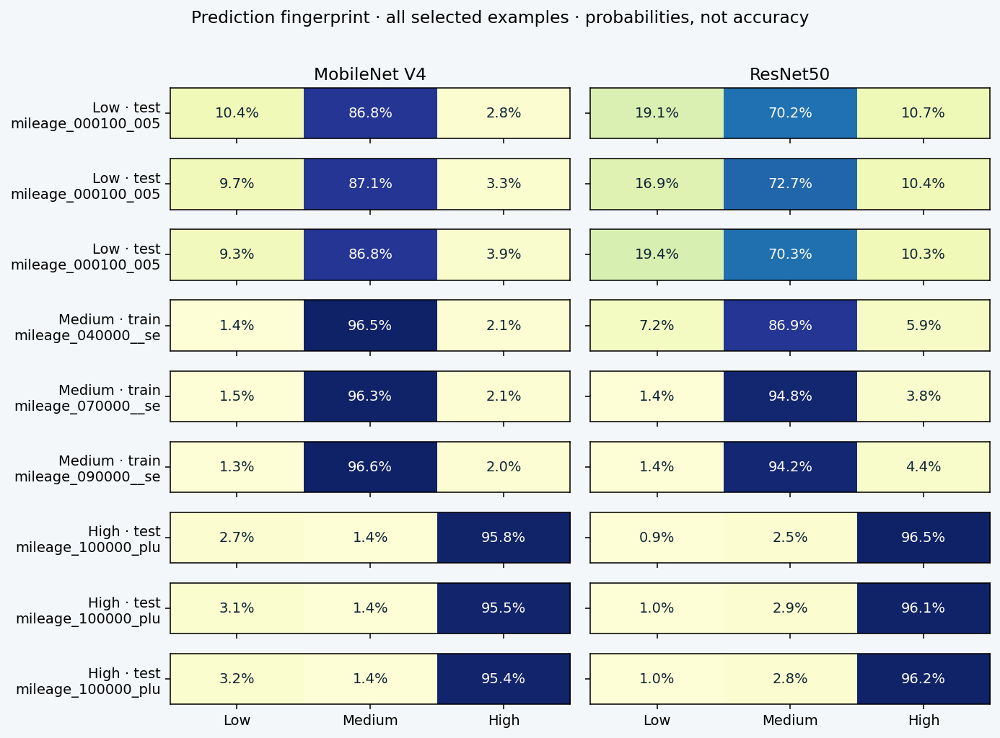

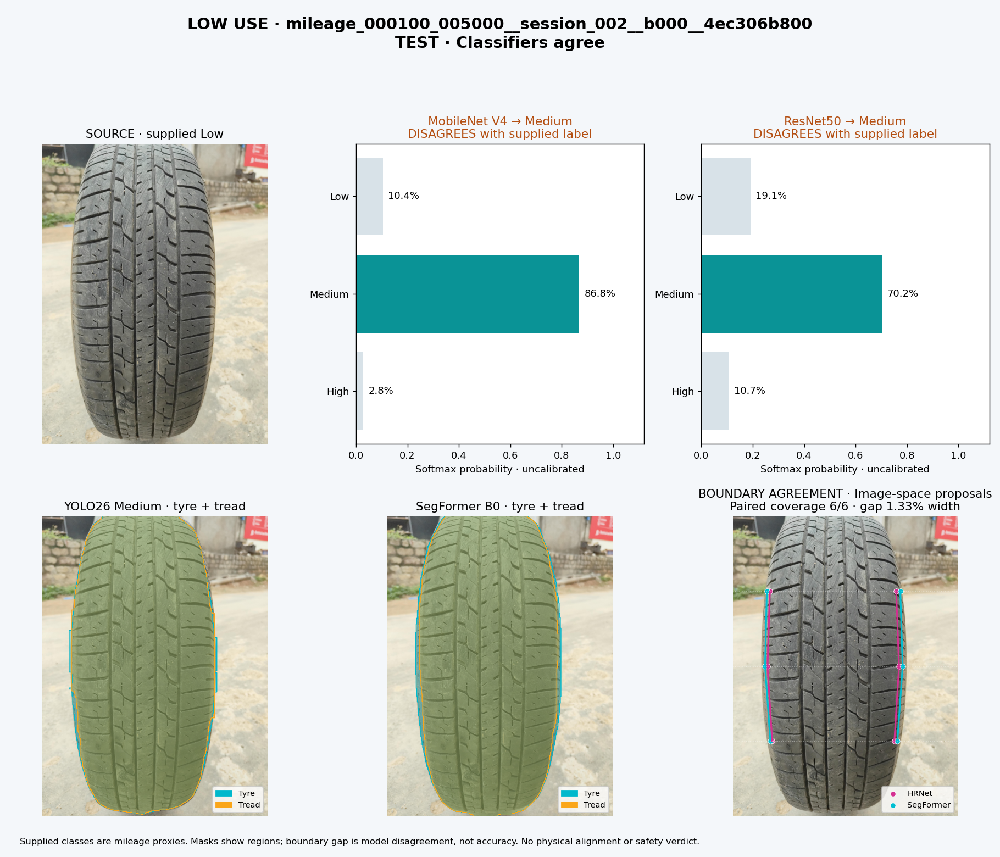

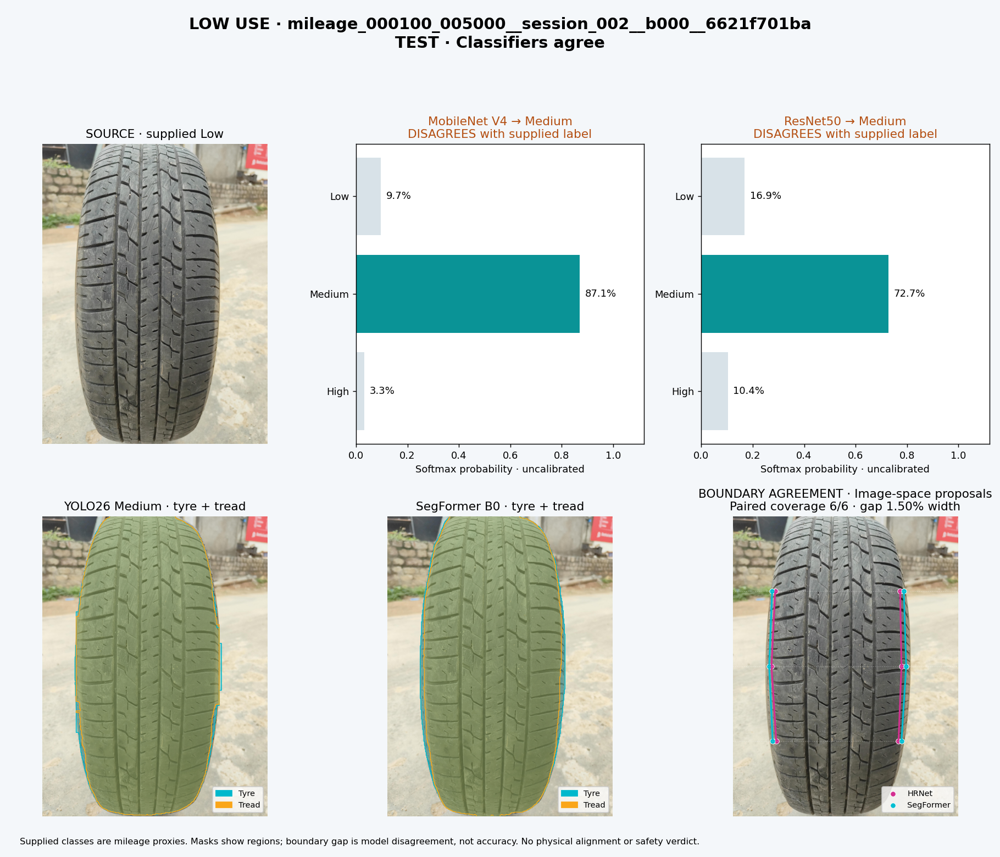

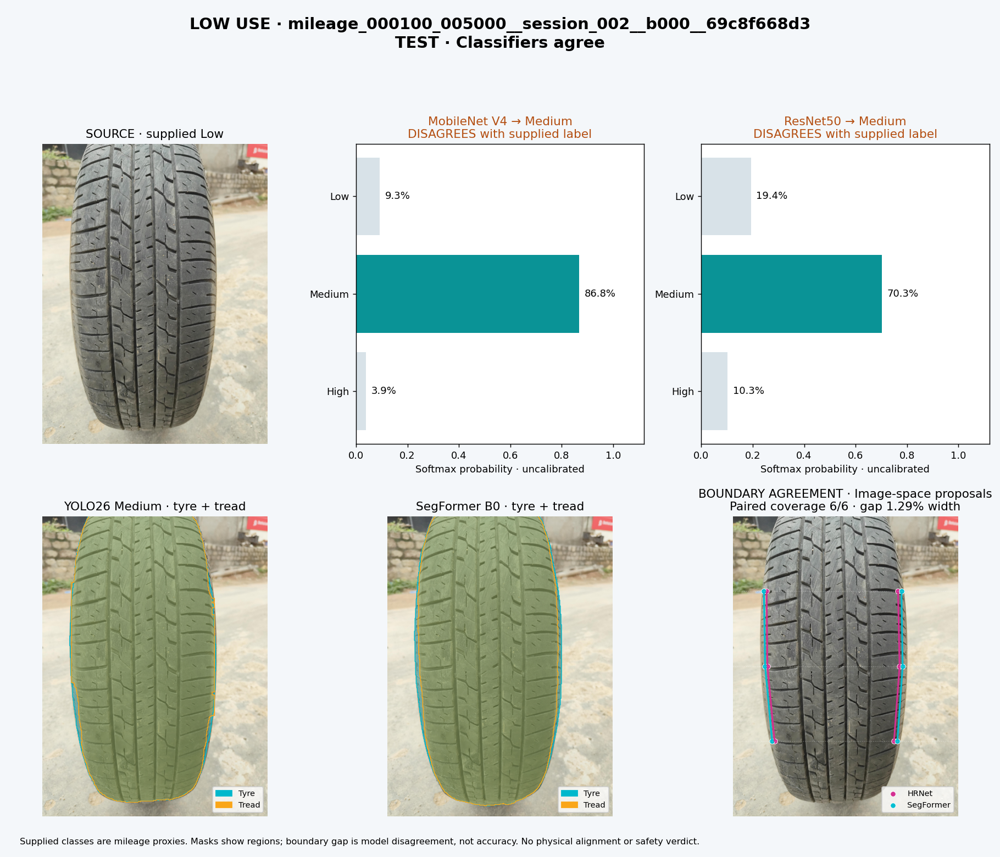

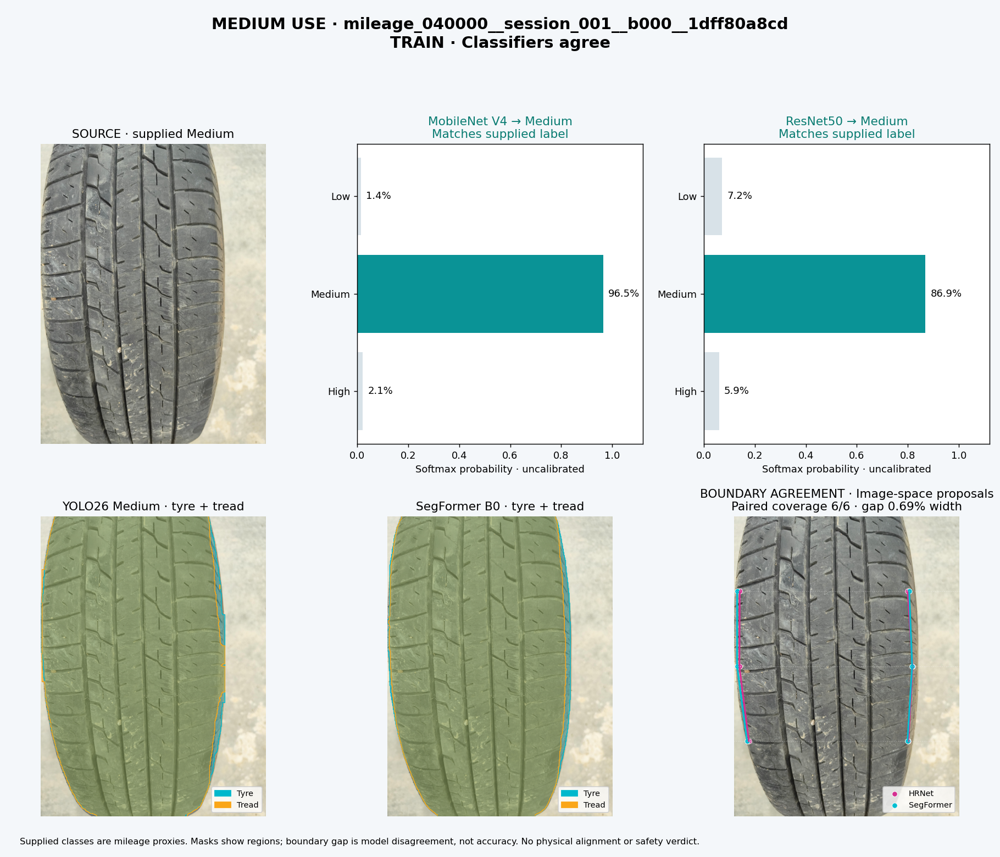

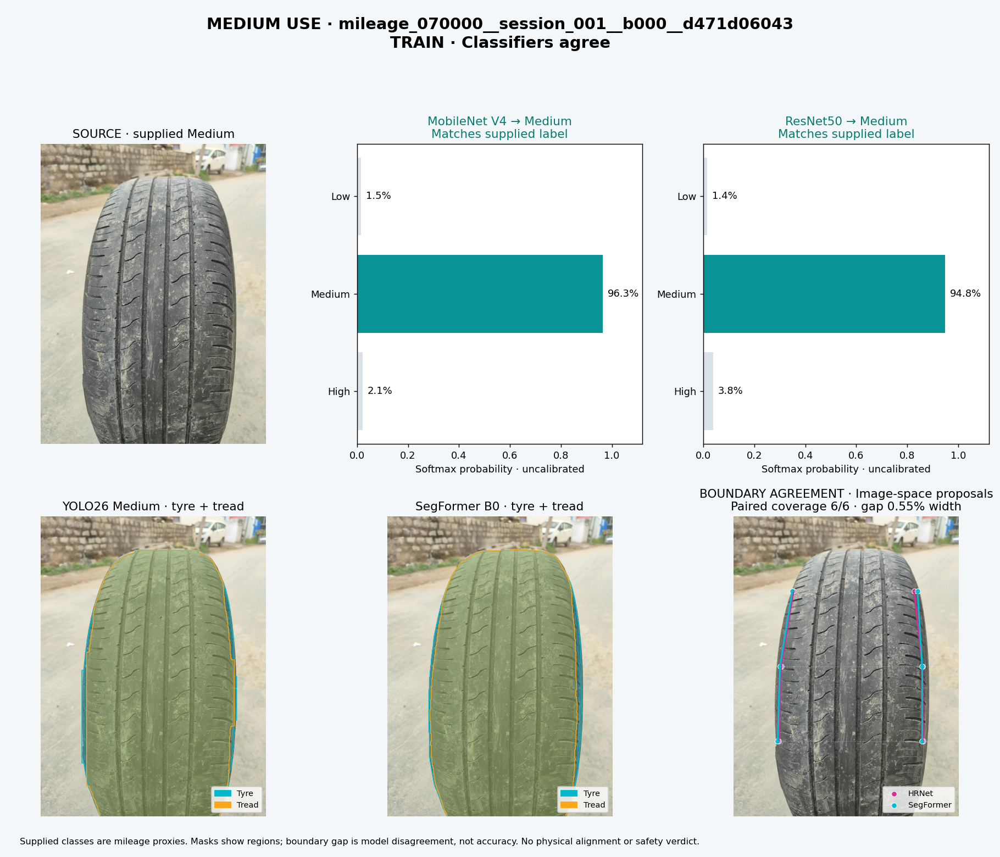

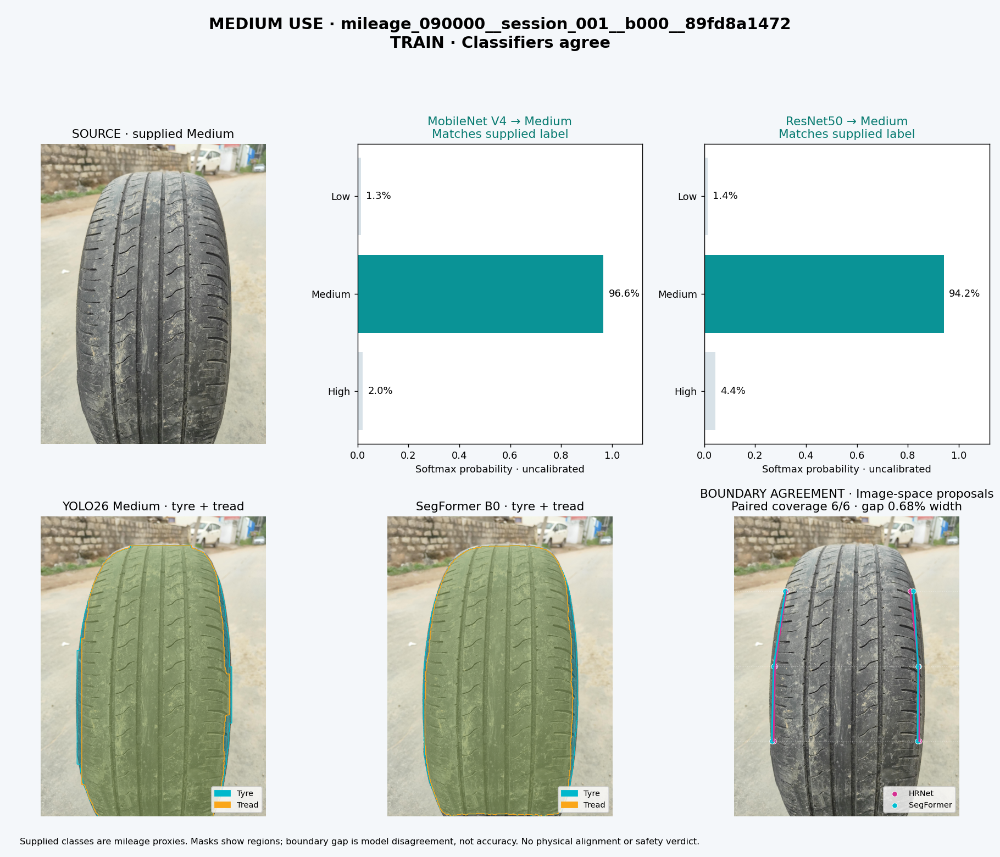

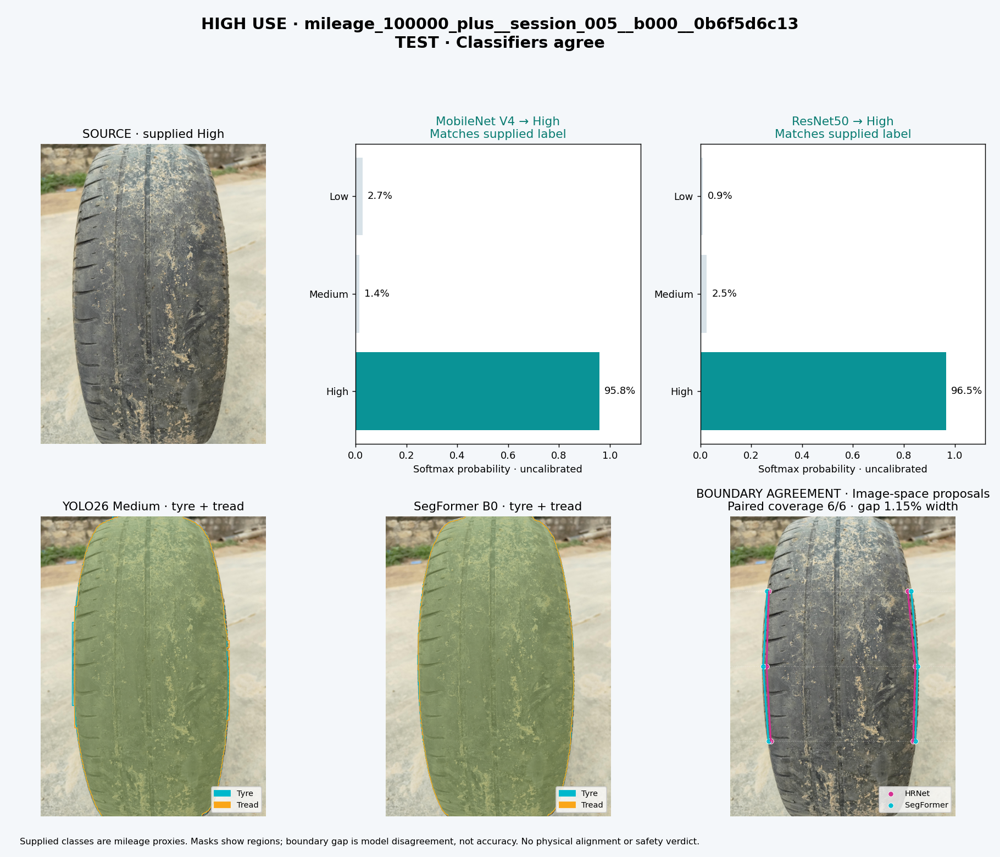

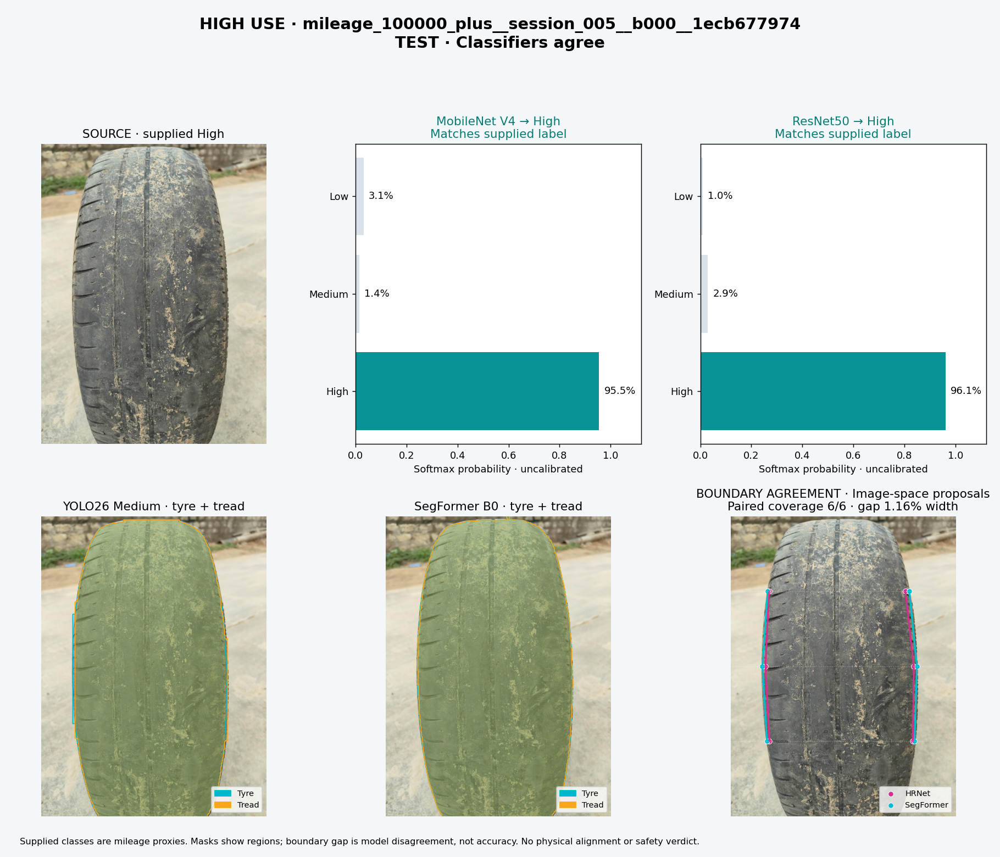

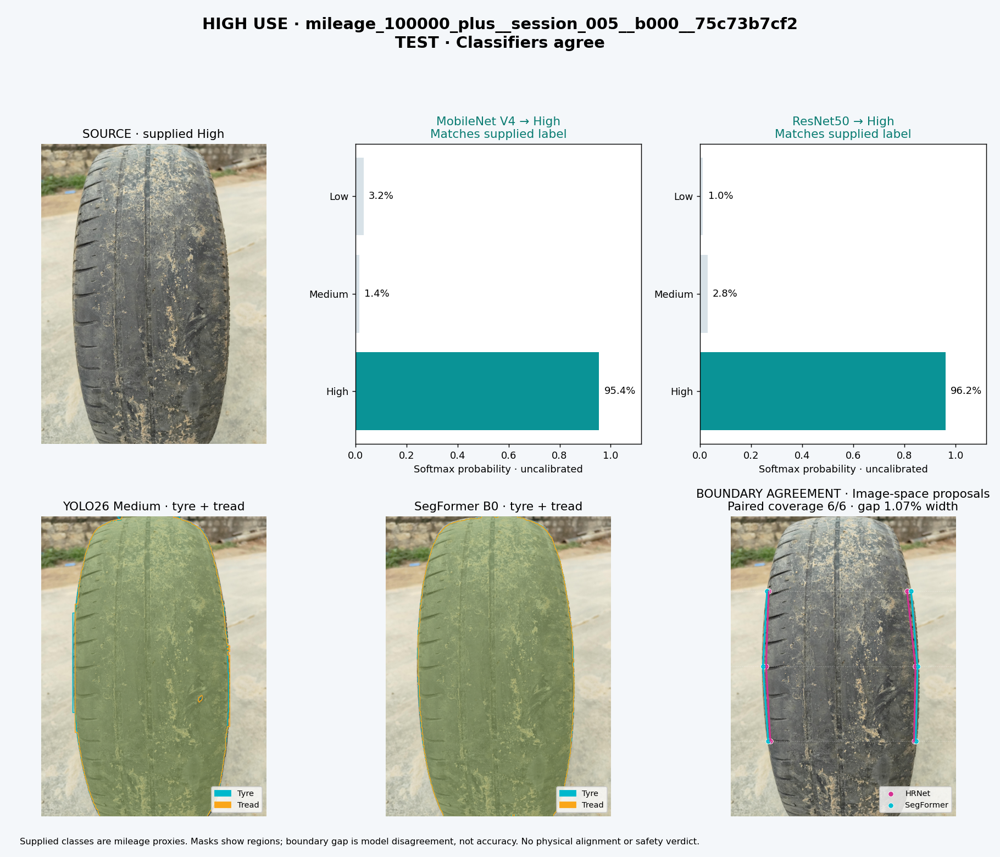

In [5]:
try:
    PANELS = studio.render(ROWS, PUBLISHER.out, REGISTRY)
    PUBLISHER.publish('gallery complete')
except BaseException:
    try: PUBLISHER.publish('gallery interrupted')
    except Exception as error: print('Upload unavailable:', type(error).__name__, 'Local outputs retained.')
    raise
display(DisplayImage(filename=str(PUBLISHER.out/'prediction_fingerprint.png')))
for panel in PANELS: display(DisplayImage(filename=str(panel)))


## 5 · Download and keep the evidence
The ZIP includes the light-theme HTML gallery, PNG cards, numerical predictions, raw masks/points, input hashes, checkpoint provenance and environment. Open `gallery.html` **after extracting the ZIP**, so its image links work. Original full-resolution source files and model weights are not duplicated in the gallery. Inference times in NPZ files are diagnostic cold/warm timings, not a benchmark.


In [6]:
import zipfile
DOWNLOAD = WORK/(RUN_ID+'-gallery.zip')
with zipfile.ZipFile(DOWNLOAD,'w',zipfile.ZIP_DEFLATED) as z:
    for p in PUBLISHER.out.rglob('*'):
        if p.is_file() and p.suffix!='.tmp': z.write(p,p.relative_to(PUBLISHER.out).as_posix())
display(FileLink(str(DOWNLOAD)))
print('Also available from Kaggle Output:', DOWNLOAD.name)
print('HF destination:', 'https://huggingface.co/datasets/'+studio.REPO+'/tree/main/'+PUBLISHER.prefix)


/kaggle/working/tyre_visual_comparison/first-comparison-900f81ad9d42b2a7-gallery.zip

Also available from Kaggle Output: first-comparison-900f81ad9d42b2a7-gallery.zip
HF destination: https://huggingface.co/datasets/Shanmuk4622/tyre-wear-study/tree/main/phase2/visual-comparison-v1/first-comparison-900f81ad9d42b2a7


### Troubleshooting
- **Wrong/missing dataset:** attach the expanded prepared Phase 2 Kaggle dataset, or set DATA_ROOT to its directory containing VERSION.json. A different release is rejected. For your own photos use CUSTOM_ROOT instead.
- **GPU memory:** the notebook loads one model at a time. Restart a fresh kernel to release allocations left by other work, then Run All; saved predictions resume.
- **Dependency/import error:** use a fresh Kaggle kernel and run setup before importing Torch model libraries elsewhere. Kaggle Torch/torchvision are preserved.
- **HF 401/403:** enable the HF_TOKEN secret and its repository write access. No token is printed or saved in outputs. On 429/network failures, allow retries; local results remain available.
- **Stop:** wait for the HF verification message. For a failed upload, rerun `PUBLISHER.publish('manual recovery')` while the files still exist. A forced kill cannot run cleanup.
- **Unexpected predictions:** retain them. Inspect cohort labels, original orientation and full probabilities; do not tune thresholds or choose prettier examples and call that an evaluation.

This notebook uses the five current production exports. Earlier Phase 1 model families and all three training seeds are a different comparison scope; no paper text is changed here.
